# Region survey + sliding Lipschitz quotients on Dandiset 000363

Limited build, per the folder README: we only load the data and look, no modelling.

1. **Region survey** — stream the electrodes table of every session of
   [Dandiset 000363](https://dandiarchive.org/dandiset/000363) (Chen et al. 2024,
   brain-wide activity during memory-guided movement) and tabulate which brain
   regions each session records. Then: which sessions hold the most regions at
   once, and which region *combinations* are shared by the most sessions.
2. **One session** — load trials + good units, bin spikes at 10 ms, SVD the
   correlation matrix of the binned counts, keep the top K PCs (elbow, or 10,
   whichever comes first), and compute the local Lipschitz constant of the
   projected trajectory over time (`||dx||/dt` and `||dv||/dt`, as in the
   bouncing-ball demo) against the trial structure. Then the same trace per
   brain region: jumps shared across regions at the same moment are the
   guard-suggestive kind.

Nothing is downloaded: files are streamed from S3 with `remfile` byte ranges, so
even the ~300 GB raw-ephys sessions only cost the arrays we touch. The survey
caches to a CSV next to this notebook and resumes if interrupted.

In [1]:
# ----------------------------- config ---------------------------------
import time
import itertools
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import remfile
import pynwb
from dandi.dandiapi import DandiAPIClient

DANDISET_ID = "000363"
SURVEY_CACHE = Path("region_survey_000363.csv")  # written next to this notebook
SURVEY_LIMIT = None      # int for a quick pass (e.g. 25); None = all 174 sessions

CHOSEN_PATH = None       # None = auto-pick the surveyed session with most regions

# binning / embedding
BIN_MS = 10.0            # spike-count bin width for the covariance/correlation
K_MAX = 10               # keep top-K PCs: the spectrum's elbow, capped at this
PAD_S = 5.0              # seconds kept before the first / after the last trial
MIN_RATE_HZ = 0.1        # drop near-silent units
MIN_UNITS_REGION = 15    # regions with fewer good units skip the per-region trace

# detection, same spirit as the bouncing-ball demo: free flight has a steady
# quotient, a reset is a huge isolated spike above a robust baseline
THRESH_MULT = 5.0        # threshold = THRESH_MULT * median(||dv||/dt)

ZOOM_START = None        # seconds; None = auto (a little before the 10th go cue)
ZOOM_DUR = 30.0          # seconds shown in the zoomed trace figure

## 1. Region survey across all sessions

The DANDI asset metadata does not carry region labels, so for each NWB file we
stream only what we need: `electrodes/location`, the unit count, and the
unit → electrode mapping (so regions are counted by *units actually recorded
there*, not just by electrode placement). A couple of small int/str arrays per
file — a few seconds each, not 300 GB.

In [4]:
import json


def _decode(arr):
    """HDF5 string data to a plain numpy array of str."""
    return np.array([x.decode() if isinstance(x, (bytes, bytearray)) else str(x)
                     for x in np.asarray(arr)])


def region_name(loc):
    """Brain region from an electrode `location` string.

    000363 stores a JSON blob per electrode, e.g.
    {"brain_regions": "left ALM", "ap_location": ..., ...}; other datasets
    store the plain name. Either way, return just the region."""
    s = str(loc).strip()
    if s.startswith("{"):
        try:
            return str(json.loads(s).get("brain_regions", "")).strip()
        except ValueError:
            pass
    return s


def _ragged(group, col):
    """A DynamicTable ragged column as a list of per-row arrays."""
    data = group[col][:]
    if col + "_index" in group:
        return np.split(data, group[col + "_index"][:-1])
    return [np.atleast_1d(v) for v in data]


def open_stream(asset):
    url = asset.get_content_url(follow_redirects=1, strip_query=True)
    return h5py.File(remfile.File(url), "r")


def survey_session(asset):
    """One row of the survey: regions present and units per region."""
    sub, fname = asset.path.split("/", 1)
    row = {"path": asset.path, "subject": sub.replace("sub-", ""),
           "size_gb": round(asset.size / 1e9, 1),
           "n_electrodes": 0, "n_units": 0, "regions": "", "units_per_region": "",
           "error": ""}
    with open_stream(asset) as f:
        elec = f.get("general/extracellular_ephys/electrodes")
        if elec is None or "location" not in elec:
            row["error"] = "no electrodes table"
            return row
        loc = np.array([region_name(s) for s in _decode(elec["location"][:])])
        row["n_electrodes"] = len(loc)

        units = f.get("units")
        per_region = Counter()
        if units is not None and "id" in units:
            row["n_units"] = len(units["id"])
            if "electrodes" in units:
                # region of a unit = location of its first electrode
                first_elec = [int(e[0]) for e in _ragged(units, "electrodes") if len(e)]
                per_region = Counter(loc[first_elec])
        if not per_region:               # fall back to electrode placement
            per_region = Counter(loc)
        per_region = Counter({k: v for k, v in per_region.items()
                              if k and k.lower() not in ("none", "n/a", "unknown")})
        row["regions"] = ";".join(sorted(per_region))
        row["units_per_region"] = ";".join(
            "%s=%d" % kv for kv in sorted(per_region.items()))
    return row


In [5]:
def _clean_row(row):
    """Region labels via region_name -- also fixes rows cached before it existed."""
    row = dict(row)
    per_region = Counter()
    for item in str(row.get("units_per_region", "") or "").split(";"):
        if "=" in item:
            name, n = item.rsplit("=", 1)
            name = region_name(name)
            if name:
                per_region[name] += int(float(n))
    row["regions"] = ";".join(sorted(per_region))
    row["units_per_region"] = ";".join("%s=%d" % kv for kv in sorted(per_region.items()))
    return row


cache = {}
if SURVEY_CACHE.exists():
    cache = {r["path"]: dict(r) for _, r in pd.read_csv(
        SURVEY_CACHE, keep_default_na=False).iterrows()}

with DandiAPIClient() as client:
    dandiset = client.get_dandiset(DANDISET_ID, "draft")
    assets = sorted((a for a in dandiset.get_assets() if a.path.endswith(".nwb")),
                    key=lambda a: a.path)
    if SURVEY_LIMIT is not None:
        assets = assets[:SURVEY_LIMIT]
    todo = [a for a in assets
            if not (a.path in cache and not cache[a.path].get("error"))]
    print("%d sessions: %d cached, %d to stream" % (
        len(assets), len(assets) - len(todo), len(todo)))

    t_start = time.time()
    for i, asset in enumerate(todo):
        try:
            row = survey_session(asset)
        except Exception as exc:                       # keep going, log the file
            row = {"path": asset.path, "error": "%s: %s" % (type(exc).__name__, exc)}
        cache[asset.path] = row
        pd.DataFrame(cache.values()).to_csv(SURVEY_CACHE, index=False)
        print("\r  streamed %3d/%3d  (%4.0fs)  %-70s" % (
            i + 1, len(todo), time.time() - t_start, asset.path), end="", flush=True)
    print()

# ---------------------------- summary ------------------------------------
survey = pd.DataFrame([_clean_row(r) for r in cache.values()])
survey["error"] = survey["error"].fillna("").astype(str)
failed = survey[survey["error"] != ""]
survey = survey[survey["error"] == ""].reset_index(drop=True)
survey["session"] = survey["path"].str.extract(r"ses-([^_]+)")[0]
survey["n_units"] = pd.to_numeric(survey["n_units"], errors="coerce").fillna(0).astype(int)
survey["n_regions"] = survey["regions"].map(lambda r: len([x for x in r.split(";") if x]))

print("surveyed OK: %d sessions, %d subjects, %d failed" % (
    len(survey), survey["subject"].nunique(), len(failed)))

# long form: one row per (session, region)
long = pd.DataFrame([
    {"path": r.path, "subject": r.subject, "region": name, "units": int(n)}
    for r in survey.itertuples()
    for name, n in (x.rsplit("=", 1) for x in r.units_per_region.split(";") if "=" in x)
])

# 1) how many regions do sessions record at once?
by_count = (survey.groupby("n_regions")
            .agg(sessions=("path", "size"), subjects=("subject", "nunique"),
                 median_units=("n_units", "median"))
            .sort_index(ascending=False))
print("\nsessions by number of simultaneously recorded regions:")
display(by_count)

# 2) per region: how many sessions / subjects / units
region_table = (long.groupby("region")
                .agg(sessions=("path", "nunique"), subjects=("subject", "nunique"),
                     total_units=("units", "sum"), median_units=("units", "median"))
                .sort_values("sessions", ascending=False))
print("\nper region:")
display(region_table)

# 3) the sessions with the most regions
top_sessions = (survey.sort_values(["n_regions", "n_units"], ascending=False)
                [["subject", "session", "n_regions", "n_units", "regions"]]
                .assign(regions=lambda d: d["regions"].str.replace(";", ", "))
                .head(15).reset_index(drop=True))
print("\ntop 15 sessions by number of regions:")
display(top_sessions)

if len(failed):
    print("\nfailed sessions:")
    display(failed[["path", "error"]].reset_index(drop=True))


174 sessions: 174 cached, 0 to stream

surveyed OK: 174 sessions, 28 subjects, 0 failed

sessions by number of simultaneously recorded regions:


,sessions,subjects,median_units
n_regions,,,
5,1,1,2367.0
4,114,24,1783.0
3,56,17,1013.5
2,3,3,892.0



per region:


,sessions,subjects,total_units,median_units
region,,,,
left ALM,108,28,44515,403.0
right ALM,103,28,41839,397.0
right Midbrain,68,22,25968,375.5
left Midbrain,68,20,24645,374.5
right Striatum,57,19,23795,394.0
left Striatum,54,19,20844,379.0
left Thalamus,45,15,23981,489.0
right Thalamus,36,13,18406,468.5
right Medulla,24,8,11913,360.5



top 15 sessions by number of regions:


,subject,session,n_regions,n_units,regions
0,480133,20201230T112558,5,2367,"left ALM, left Midbrain, left Thalamus, right ..."
1,480928,20210128T133949,4,3191,"left ALM, left Thalamus, right ALM, right Thal..."
2,479121,20200924T134307,4,2778,"left ALM, left Medulla, right ALM, right Medulla"
3,480928,20210130T135022,4,2699,"left ALM, left BLA, right ALM, right BLA"
4,479121,20200923T151145,4,2685,"left ALM, left Medulla, right ALM, right Medulla"
5,480134,20210108T135220,4,2648,"left ECT, left Striatum, right Midbrain, right..."
6,480928,20210129T132207,4,2632,"left ALM, left Thalamus, right ALM, right Thal..."
7,480134,20210113T125455,4,2619,"left ALM, left Thalamus, right ALM, right Thal..."
8,480928,20210127T140737,4,2596,"left ALM, left Thalamus, right ALM, right Thal..."
9,484677,20210418T132006,4,2506,"left Medulla, right ALM, right Midbrain, right..."


14 distinct region labels: left ALM, left BLA, left ECT, left Medulla, left Midbrain, left Striatum, left Thalamus, right ALM, right BLA, right ECT, right Medulla, right Midbrain, right Striatum, right Thalamus

sessions with the most regions at once:
                                                               path  subject  n_regions  n_units                                                       regions
sub-480133/sub-480133_ses-20201230T112558_behavior+ecephys+ogen.nwb   480133          5     2367 left ALM;left Midbrain;left Thalamus;right ALM;right Thalamus
sub-480928/sub-480928_ses-20210128T133949_behavior+ecephys+ogen.nwb   480928          4     3191               left ALM;left Thalamus;right ALM;right Thalamus
sub-479121/sub-479121_ses-20200924T134307_behavior+ecephys+ogen.nwb   479121          4     2778                 left ALM;left Medulla;right ALM;right Medulla
sub-480928/sub-480928_ses-20210130T135022_behavior+ecephys+ogen.nwb   480928          4     2699                

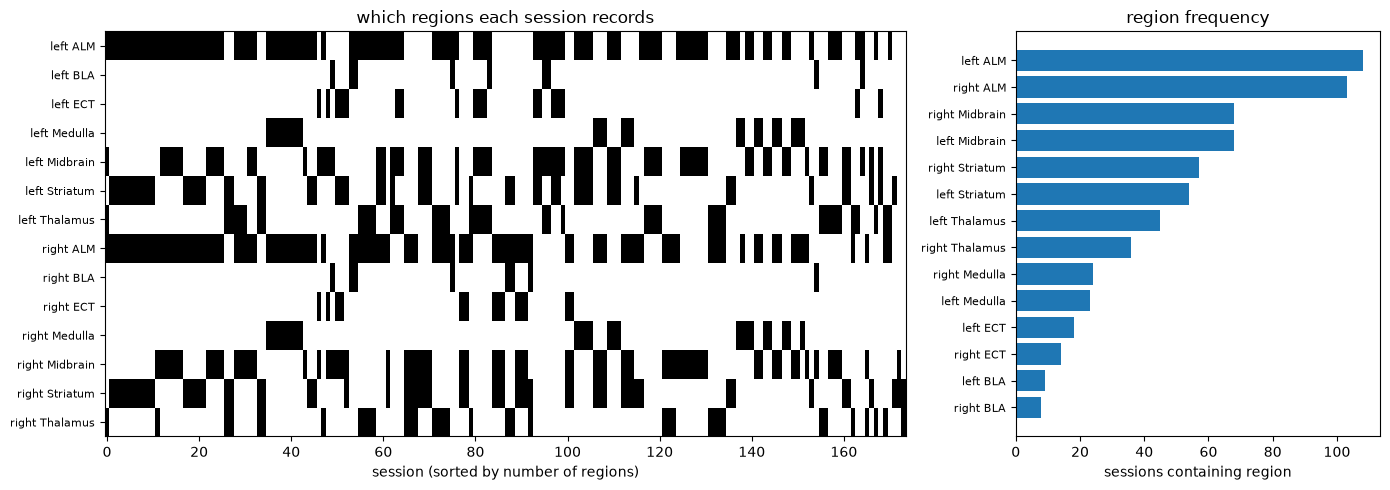

In [6]:
# ---------------- sessions x regions presence matrix -------------------
region_sets = [set(r.split(";")) - {""} for r in survey["regions"]]
all_regions = sorted(set().union(*region_sets))
presence = np.array([[reg in s for reg in all_regions] for s in region_sets])
print("%d distinct region labels: %s" % (len(all_regions), ", ".join(all_regions)))

ranked = survey.sort_values(["n_regions", "n_units"], ascending=False)
print("\nsessions with the most regions at once:")
print(ranked[["path", "subject", "n_regions", "n_units", "regions"]]
      .head(12).to_string(index=False))

order = np.argsort(-survey["n_regions"].values, kind="stable")
fig, axes = plt.subplots(1, 2, figsize=(14, 5),
                         gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
ax.imshow(presence[order].T, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(all_regions)))
ax.set_yticklabels(all_regions, fontsize=8)
ax.set_xlabel("session (sorted by number of regions)")
ax.set_title("which regions each session records")

ax = axes[1]
freq = presence.sum(0)
fo = np.argsort(freq)
ax.barh(range(len(all_regions)), freq[fo], color="tab:blue")
ax.set_yticks(range(len(all_regions)))
ax.set_yticklabels(np.array(all_regions)[fo], fontsize=8)
ax.set_xlabel("sessions containing region")
ax.set_title("region frequency")
plt.tight_layout()
plt.show()

In [7]:
# -------- region combinations: what do many sessions share? ------------
# exact recorded sets
set_counts = Counter(frozenset(s) for s in region_sets)
print("most common exact region sets:")
for s, n in set_counts.most_common(10):
    print("  %3d sessions  (%d regions)  %s" % (n, len(s), ", ".join(sorted(s))))

# best k-region combination shared by the most sessions: for each k, the combo
# of regions that the largest number of sessions ALL contain
print("\nbest shared combination per combination size k:")
rows = []
for k in range(2, min(len(all_regions), 8) + 1):
    best = []
    for combo in itertools.combinations(range(len(all_regions)), k):
        n = int(presence[:, combo].all(axis=1).sum())
        if n:
            best.append((n, combo))
    if not best:
        break
    best.sort(reverse=True)
    for n, combo in best[:3]:
        rows.append({"k": k, "sessions": n,
                     "regions": ", ".join(all_regions[i] for i in combo)})
        print("  k=%d  %3d sessions  %s" % (k, n, rows[-1]["regions"]))
combo_table = pd.DataFrame(rows)

most common exact region sets:
   17 sessions  (4 regions)  left ALM, left Striatum, right ALM, right Striatum
   12 sessions  (4 regions)  left ALM, left Midbrain, right ALM, right Midbrain
   10 sessions  (4 regions)  right ALM, right ECT, right Midbrain, right Striatum
    8 sessions  (4 regions)  left ALM, left Medulla, right ALM, right Medulla
    8 sessions  (4 regions)  left ALM, left Thalamus, right ALM, right Thalamus
    7 sessions  (4 regions)  left ALM, left Midbrain, left Striatum, right Medulla
    6 sessions  (3 regions)  left ALM, left Midbrain, right Midbrain
    6 sessions  (3 regions)  left Thalamus, right ALM, right Thalamus
    6 sessions  (3 regions)  left ALM, left Midbrain, right Medulla
    6 sessions  (3 regions)  left Medulla, right ALM, right Midbrain

best shared combination per combination size k:
  k=2   60 sessions  left ALM, right ALM
  k=2   55 sessions  left ALM, left Midbrain
  k=2   48 sessions  right ALM, right Midbrain
  k=3   20 sessions  right A

## 2. One session: trial structure vs the Lipschitz constant of the top PCs

Pick the surveyed session with the most simultaneous regions (override with
`CHOSEN_PATH`), stream it, and build a light units table — spike times, region,
quality — without pulling waveforms or raw ephys.

In [8]:
# ------------------- choose the session --------------------------------
CHOSEN_SUBJECT = "480928"            # bilateral ALM + bilateral thalamus
CHOSEN_SESSION = "20210128T133949"   # most units of the 4-region sessions

match = survey[(survey["subject"].astype(str) == CHOSEN_SUBJECT)
               & (survey["session"] == CHOSEN_SESSION)]
if len(match):
    CHOSEN_PATH = match["path"].iloc[0]
elif CHOSEN_PATH is None:
    print("session %s / %s not in survey, falling back to most-region session"
          % (CHOSEN_SUBJECT, CHOSEN_SESSION))
    CHOSEN_PATH = ranked.iloc[0]["path"]
print("loading:", CHOSEN_PATH)

with DandiAPIClient() as client:
    asset = client.get_dandiset(DANDISET_ID, "draft").get_asset_by_path(CHOSEN_PATH)
    s3_url = asset.get_content_url(follow_redirects=1, strip_query=True)

h5f = h5py.File(remfile.File(s3_url), "r")
io = pynwb.NWBHDF5IO(file=h5f, load_namespaces=True)
nwb = io.read()
print(nwb.session_description)

# --- light units table straight from the HDF5 group (skips waveforms) ---
ug = h5f["units"]
print("units table columns:", [k for k in ug.keys() if not k.endswith("_index")])

spike_trains = _ragged(ug, "spike_times")
elec_loc = np.array([region_name(s) for s in
                     _decode(h5f["general/extracellular_ephys/electrodes/location"][:])])
unit_region = np.array([elec_loc[int(e[0])] if len(e) else ""
                        for e in _ragged(ug, "electrodes")])

quality = None
for cand in ("classification", "unit_quality", "quality", "label"):
    if cand in ug:
        quality = np.array([s.strip() for s in _decode(ug[cand][:])])
        print("quality column: %r, values: %s" % (cand, dict(Counter(quality))))
        break

units = pd.DataFrame({"region": unit_region,
                      "n_spikes": [len(s) for s in spike_trains]})
units["spike_times"] = spike_trains
if quality is not None:
    units["quality"] = quality
    units = units[units["quality"].str.lower().str.contains("good")]

# ------------------- trials, photostim trials removed --------------------
trials_all = nwb.trials.to_dataframe()
# session window comes from ALL trials, so binning covers the whole session
t0 = float(trials_all["start_time"].min()) - PAD_S
t1 = float(trials_all["stop_time"].max()) + PAD_S

trials_df = trials_all
if "photostim_onset" in trials_all:
    print("photostim_onset values (first 10 distinct):",
          trials_all["photostim_onset"].astype(str).unique()[:10])
    no_stim = trials_all["photostim_onset"].astype(str).str.strip().isin(
        ["N/A", "nan", "NaN", "None", ""])
    print("photostim trials: %d of %d removed" % ((~no_stim).sum(), len(trials_all)))
    trials_df = trials_all[no_stim].reset_index(drop=True)
else:
    print("no photostim_onset column; keeping all %d trials" % len(trials_all))
    
units["rate_hz"] = units["n_spikes"] / (t1 - t0)
n_before = units["region"].value_counts()
units = units[units["rate_hz"] >= MIN_RATE_HZ].reset_index(drop=True)

unit_table = (units.groupby("region")
              .agg(units=("rate_hz", "size"),
                   median_rate_hz=("rate_hz", "median"),
                   mean_rate_hz=("rate_hz", "mean"),
                   total_spikes=("n_spikes", "sum"))
              .assign(dropped_low_rate=lambda d: n_before.reindex(d.index).fillna(0).astype(int) - d["units"])
              .sort_values("units", ascending=False))
unit_table.loc["total"] = [unit_table["units"].sum(), units["rate_hz"].median(),
                           units["rate_hz"].mean(), unit_table["total_spikes"].sum(),
                           unit_table["dropped_low_rate"].sum()]
unit_table = unit_table.astype({"units": int, "total_spikes": int, "dropped_low_rate": int})
display(unit_table.style.format({"median_rate_hz": "{:.2f}", "mean_rate_hz": "{:.2f}",
                                 "total_spikes": "{:,}"})
        .set_caption("Good units kept per region (rate ≥ %.2f Hz)" % MIN_RATE_HZ))


loading: sub-480928/sub-480928_ses-20210128T133949_behavior+ecephys+ogen.nwb

units table columns: ['amplitude_cutoff', 'anno_name', 'avg_firing_rate', 'classification', 'cumulative_drift', 'd_prime', 'drift_metric', 'duration', 'electrode_group', 'electrodes', 'halfwidth', 'id', 'is_good_trials', 'isi_violation', 'isolation_distance', 'l_ratio', 'left_trials_drift_metric', 'max_drift', 'nn_hit_rate', 'nn_miss_rate', 'obs_intervals', 'presence_ratio', 'pt_ratio', 'recovery_slope', 'repolarization_slope', 'right_trials_drift_metric', 'sampling_rate', 'silhouette_score', 'spike_times', 'spread', 'unit', 'unit_amp', 'unit_posx', 'unit_posy', 'unit_quality', 'unit_snr', 'velocity_above', 'velocity_below', 'waveform_mean', 'waveform_sd']
quality column: 'classification', values: {np.str_('unlabelled'): 2268, np.str_('good'): 923}
photostim_onset values (first 10 distinct): <StringArray>
[  'N/A', '2.640', '2.686', '2.586', '2.579', '2.724', '3.610', '3.486',
 '2.706', '2.750']
Length: 10, d

,units,median_rate_hz,mean_rate_hz,total_spikes,dropped_low_rate
region,,,,,
right Thalamus,357,4.57,5.76,"9,227,884",0
right ALM,208,1.32,2.46,"2,292,744",4
left Thalamus,185,6.87,8.24,"6,834,326",0
left ALM,166,2.18,3.25,"2,422,047",3
total,916,3.75,5.06,"20,777,001",7


In [9]:
# ------------------------- trial structure -----------------------------
print("%d trials, columns:" % len(trials_df), list(trials_df.columns))
display(trials_df.head())

# task epoch events (sample / delay / go cues) live in BehavioralEvents
events = {}
beh = nwb.acquisition.get("BehavioralEvents")
if beh is not None:
    for name, ts in beh.time_series.items():
        if any(k in name.lower() for k in ("sample", "delay", "go")):
            events[name] = np.asarray(ts.timestamps[:])
for name, tt in sorted(events.items()):
    print("%-28s %6d events" % (name, len(tt)))

go_key = next((k for k in events if "go" in k.lower()), None)
go_times = events.get(go_key)
print("\nusing %r as the go cue" % go_key)

524 trials, columns: ['start_time', 'stop_time', 'trial', 'photostim_onset', 'photostim_power', 'photostim_duration', 'trial_uid', 'task', 'task_protocol', 'trial_instruction', 'early_lick', 'outcome', 'auto_water', 'free_water']


,start_time,stop_time,trial,photostim_onset,photostim_power,photostim_duration,trial_uid,task,task_protocol,trial_instruction,early_lick,outcome,auto_water,free_water
0,0.0000,5.6018,1,N/A,N/A,N/A,1,audio delay,1,right,early,ignore,0,0
1,7.3943,11.6188,2,N/A,N/A,N/A,2,audio delay,1,right,no early,miss,0,0
2,14.0939,18.3118,3,N/A,N/A,N/A,3,audio delay,1,right,no early,miss,0,0
3,20.1039,24.1155,4,N/A,N/A,N/A,4,audio delay,1,right,no early,miss,0,0
4,25.9083,30.8638,5,N/A,N/A,N/A,5,audio delay,1,right,no early,ignore,0,0


delay_start_times               636 events
delay_stop_times                636 events
go_start_times                  620 events
go_stop_times                   620 events
presample_start_times           620 events
presample_stop_times            620 events
sample_start_times              735 events
sample_stop_times               735 events

using 'go_start_times' as the go cue


binned counts: (448572, 916) (74.8 min at 10 ms bins)
elbow at 5, K_MAX 10 -> keeping K = 5 PCs (4.6% of correlation variance)


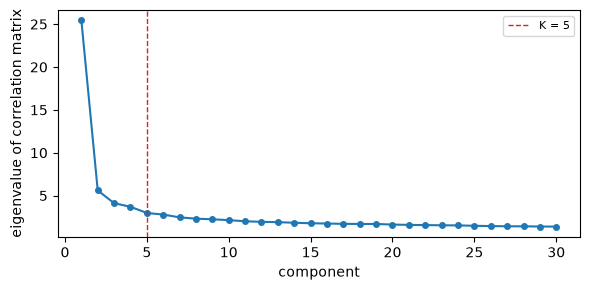

In [10]:
# -------- bin at 10 ms, SVD the correlation matrix, elbow-pick K ---------
dt = BIN_MS / 1000.0
edges = np.arange(t0, t1, dt)
tb = edges[:-1] + dt / 2

X = np.empty((len(tb), len(units)), dtype=np.float32)
for j, st in enumerate(units["spike_times"]):
    X[:, j], _ = np.histogram(st, bins=edges)
print("binned counts:", X.shape, "(%.1f min at %g ms bins)" % (
    (t1 - t0) / 60, BIN_MS))


def corr_svd(counts):
    """Correlation matrix of binned counts -> (eigenvalues desc, eigenvectors,
    z-scored counts). Z-scoring the units makes cov(Z) the correlation of X."""
    Z = counts - counts.mean(0)
    Z /= np.maximum(counts.std(0), 1e-9)
    corr = (Z.T @ Z) / (len(Z) - 1)
    evals, evecs = np.linalg.eigh(corr)
    return evals[::-1], evecs[:, ::-1], Z


def elbow_k(evals, k_max, m=50):
    """Elbow = eigenvalue farthest below the chord through the leading
    spectrum; K = min(elbow, k_max) -- whichever comes first."""
    m = min(m, len(evals))
    y = evals[:m]
    chord = y[0] + (y[-1] - y[0]) * np.arange(m) / (m - 1)
    return min(int(np.argmax(chord - y)) + 1, k_max)


evals, evecs, Z = corr_svd(X)
K = elbow_k(evals, K_MAX)
x = Z @ evecs[:, :K]               # (time, K) trajectory
print("elbow at %d, K_MAX %d -> keeping K = %d PCs (%.1f%% of correlation "
      "variance)" % (elbow_k(evals, 10**9), K_MAX, K,
                     100 * evals[:K].sum() / evals.sum()))

fig, ax = plt.subplots(figsize=(6, 3))
n_show = min(30, len(evals))
ax.plot(np.arange(1, n_show + 1), evals[:n_show], "o-", color="tab:blue", ms=4)
ax.axvline(K, color="tab:red", ls="--", lw=1, label="K = %d" % K)
ax.set_xlabel("component")
ax.set_ylabel("eigenvalue of correlation matrix")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

threshold = 2.31e+05;  54 detections in 74.8 min (0.72 per min)


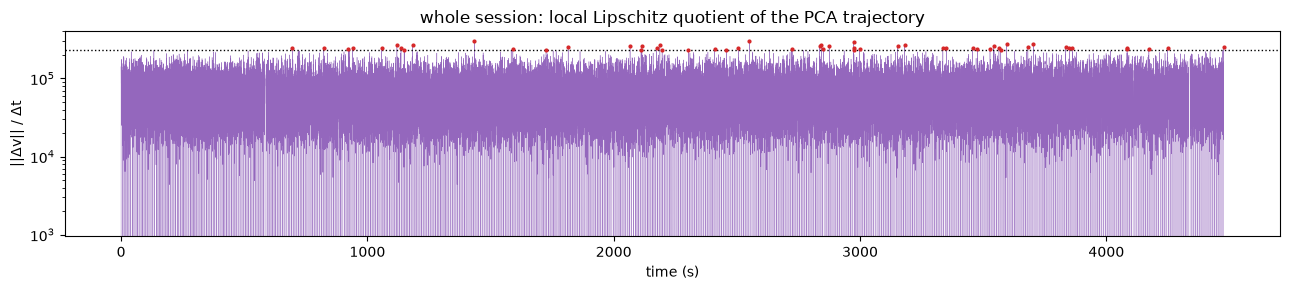

In [11]:
# -------------- sliding local Lipschitz quotients -----------------------
# As in the bouncing-ball demo: on a smooth flow ||dv||/dt stays near a steady
# baseline; a guard/reset shows up as an isolated spike orders of magnitude above.
Lp = np.linalg.norm(np.diff(x, axis=0), axis=1) / dt          # ||dp|| / dt
v = np.diff(x, axis=0) / dt
Lv = np.linalg.norm(np.diff(v, axis=0), axis=1) / dt          # ||dv|| / dt
t_p = tb[:-1] + dt / 2
t_v = tb[1:-1]

threshold = THRESH_MULT * np.median(Lv)
detected = Lv > threshold
det_times = t_v[detected]
print("threshold = %.3g;  %d detections in %.1f min (%.2f per min)" % (
    threshold, detected.sum(), (t1 - t0) / 60,
    detected.sum() / ((t1 - t0) / 60)))

# full-session overview
fig, ax = plt.subplots(figsize=(13, 3))
ax.semilogy(t_v, Lv, color="tab:purple", lw=0.3)
ax.axhline(threshold, color="k", ls=":", lw=1)
ax.plot(det_times, Lv[detected], ".", color="tab:red", ms=4)
ax.set_xlabel("time (s)")
ax.set_ylabel("||\u0394v|| / \u0394t")
ax.set_title("whole session: local Lipschitz quotient of the PCA trajectory")
plt.tight_layout()
plt.show()

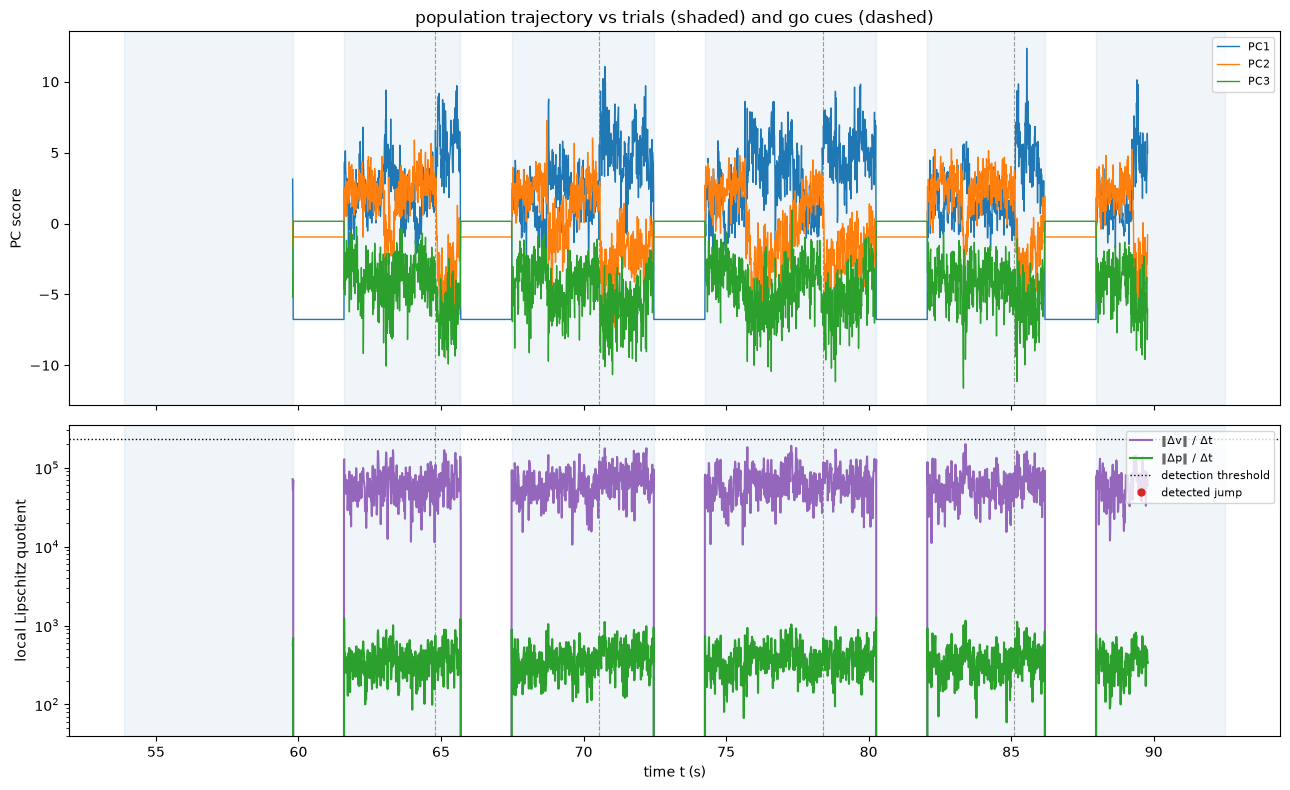

In [12]:
# -------------------- zoomed trace against the trials -------------------
if ZOOM_START is None:
    ZOOM_START = (go_times[9] - 5.0 if go_times is not None and len(go_times) > 10
                  else t0 + 60.0)
z0, z1 = ZOOM_START, ZOOM_START + ZOOM_DUR
mb = (tb >= z0) & (tb < z1)
mv = (t_v >= z0) & (t_v < z1)
mp = (t_p >= z0) & (t_p < z1)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                         gridspec_kw={"height_ratios": [1.2, 1]})
for ax in axes:
    for _, tr in trials_df.iterrows():
        if tr["stop_time"] > z0 and tr["start_time"] < z1:
            ax.axvspan(tr["start_time"], tr["stop_time"],
                       color="tab:blue", alpha=0.07, zorder=0)
    if go_times is not None:
        for g in go_times[(go_times >= z0) & (go_times < z1)]:
            ax.axvline(g, color="0.6", ls="--", lw=0.8, zorder=0)

ax = axes[0]
for i in range(min(3, K)):
    ax.plot(tb[mb], x[mb, i], lw=1, label="PC%d" % (i + 1))
ax.set_ylabel("PC score")
ax.set_title("population trajectory vs trials (shaded) and go cues (dashed)")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
ax.semilogy(t_v[mv], Lv[mv], color="tab:purple", label="\u2016\u0394v\u2016 / \u0394t")
ax.semilogy(t_p[mp], Lp[mp], color="tab:green", label="\u2016\u0394p\u2016 / \u0394t")
ax.axhline(threshold, color="k", ls=":", lw=1, label="detection threshold")
sel = detected & mv
ax.plot(t_v[sel], Lv[sel], "o", color="tab:red", ms=5, label="detected jump")
ax.set_ylabel("local Lipschitz quotient")
ax.set_xlabel("time t (s)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

left ALM                     166 units  K= 6  1962 jumps
left Thalamus                185 units  K= 4   336 jumps
right ALM                    208 units  K= 7   419 jumps
right Thalamus               357 units  K= 3    76 jumps

global jumps echoed per region:
  left ALM                      29.6% of 54 global jumps
  left Thalamus                 53.7% of 54 global jumps
  right ALM                      1.9% of 54 global jumps
  right Thalamus                 9.3% of 54 global jumps


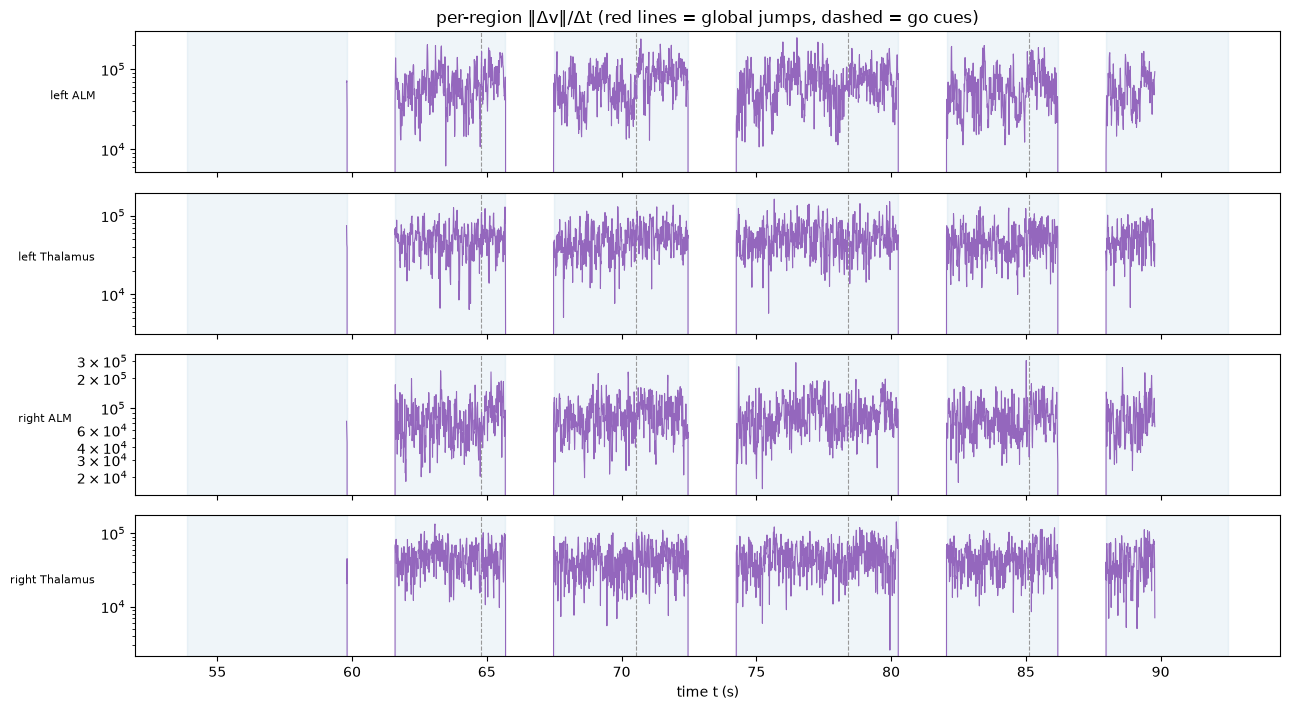

In [13]:
# ----------- do the brain regions move/jump together? -------------------
# Same recipe per region (correlation SVD, elbow-capped K, ||dv||/dt), then the
# traces stacked over the same zoom window. A jump present in several regions
# at the same bin is the guard-suggestive kind; a single-region jump is more
# likely local (movement, licks, one noisy population).
region_Lv, region_det = {}, {}
for reg, idx in sorted(units.groupby("region").indices.items()):
    if len(idx) < MIN_UNITS_REGION:
        continue
    ev_r, vec_r, Z_r = corr_svd(X[:, idx])
    k_r = elbow_k(ev_r, K_MAX)
    x_r = Z_r @ vec_r[:, :k_r]
    v_r = np.diff(x_r, axis=0) / dt
    Lv_r = np.linalg.norm(np.diff(v_r, axis=0), axis=1) / dt
    region_Lv[reg] = Lv_r
    region_det[reg] = t_v[Lv_r > THRESH_MULT * np.median(Lv_r)]
    print("%-28s %3d units  K=%2d  %4d jumps" % (
        reg, len(idx), k_r, len(region_det[reg])))

# how often does a global jump appear in each region (within +/- 3 bins)?
tol = 3 * dt
print("\nglobal jumps echoed per region:")
for reg, dts in region_det.items():
    if len(det_times):
        hit = np.mean([np.min(np.abs(dts - g)) <= tol if len(dts) else False
                       for g in det_times])
        print("  %-28s %5.1f%% of %d global jumps" % (reg, 100 * hit,
                                                      len(det_times)))

fig, axes = plt.subplots(len(region_Lv), 1, figsize=(13, 1.8 * len(region_Lv)),
                         sharex=True, squeeze=False)
for ax, (reg, Lv_r) in zip(axes[:, 0], region_Lv.items()):
    for _, tr in trials_df.iterrows():
        if tr["stop_time"] > z0 and tr["start_time"] < z1:
            ax.axvspan(tr["start_time"], tr["stop_time"],
                       color="tab:blue", alpha=0.07, zorder=0)
    if go_times is not None:
        for g in go_times[(go_times >= z0) & (go_times < z1)]:
            ax.axvline(g, color="0.6", ls="--", lw=0.8, zorder=0)
    for g in det_times[(det_times >= z0) & (det_times < z1)]:
        ax.axvline(g, color="tab:red", lw=0.8, alpha=0.6, zorder=1)
    ax.semilogy(t_v[mv], Lv_r[mv], color="tab:purple", lw=0.8)
    ax.set_ylabel(reg, rotation=0, ha="right", fontsize=8)
axes[-1, 0].set_xlabel("time t (s)")
axes[0, 0].set_title("per-region \u2016\u0394v\u2016/\u0394t "
                     "(red lines = global jumps, dashed = go cues)")
plt.tight_layout()
plt.show()

In [14]:
# --- are there spikes between trials, and was recording continuous? ---
all_spk = np.sort(np.concatenate(units["spike_times"].values))
starts = trials_all["start_time"].values
stops = trials_all["stop_time"].values
k = np.searchsorted(starts, all_spk, side="right") - 1
inside = (k >= 0) & (all_spk < stops[np.clip(k, 0, None)])
isi_gaps = np.diff(all_spk)

check = pd.Series({
    "spikes total": len(all_spk),
    "% spikes inside trials": 100 * inside.mean(),
    "% session time inside trials": 100 * np.sum(stops - starts) / (stops.max() - starts.min()),
    "median gap between trials (s)": np.median(starts[1:] - stops[:-1]),
    "population silences > 0.5 s": int(np.sum(isi_gaps > 0.5)),
    "longest population silence (s)": isi_gaps.max(),
})
display(check.to_frame("value").style.format("{:,.2f}"))

# raw voltage recordings: continuous length vs session length
rows = []
for name, obj in nwb.acquisition.items():
    if hasattr(obj, "data") and getattr(obj, "rate", None):
        rows.append({"series": name, "samples": obj.data.shape[0], "rate_hz": obj.rate,
                     "duration_min": obj.data.shape[0] / obj.rate / 60})
display(pd.DataFrame(rows) if rows else "no rate-based acquisition series")
print("session span: %.1f min" % ((stops.max() - starts.min()) / 60))


,value
spikes total,"20,777,001.00"
% spikes inside trials,100.00
% session time inside trials,68.52
median gap between trials (s),2.24
population silences > 0.5 s,619.00
longest population silence (s),5.36


,series,samples,rate_hz,duration_min
0,ElectricalSeries-1,134991705,30000.0,74.995392
1,ElectricalSeries-2,134991862,30000.0,74.995479
2,ElectricalSeries-3,134991803,30000.0,74.995446
3,ElectricalSeries-4,134992937,30000.0,74.996076
4,ElectricalSeries-5,134991892,30000.0,74.995496


session span: 74.6 min


Caveats: raw 10 ms bins are shot-noise heavy, so the quotient baseline is set
by Poisson noise and detections are relative outliers, not true Lipschitz
blow-ups — and a jump is not yet a guard/reset (licks, movement and photostim
all move the population abruptly). Per the Hybrifolds draft, smoothing is kept
out of the pipeline on purpose: it smears resets into fake fast flows. This
notebook only asks whether massive, region-shared jumps exist at all and where
they sit relative to the trials.

,value
region,right ALM
units,208
bin (ms),20.0
trials used,524
within-trial bins,129343
within-trial minutes,43.1
elbow,6
K kept,6
% correlation variance in K,7.4


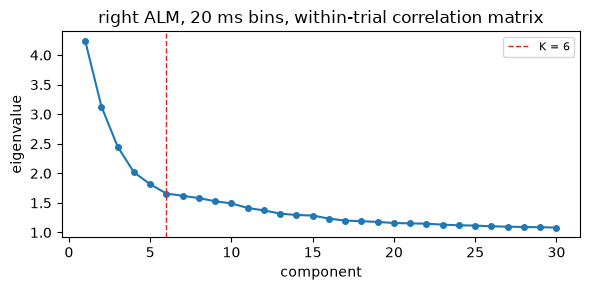

In [15]:
# ============ right ALM: within-trial SVD + Lipschitz ==================
REGION = "right ALM"
BIN_MS_R = 20.0          # bin width for this analysis -- try 10 / 20 / 50
K_MAX_R = 10             # top-K PCs: elbow or this, whichever comes first

dt_r = BIN_MS_R / 1000.0
ru = units[units["region"] == REGION].reset_index(drop=True)

# Bins are laid out per trial, starting at each trial's start time. The single
# bin bridging one trial's end to the next trial's start is built (np.histogram
# needs contiguous edges) and then dropped, so nothing outside trials is used.
edges, valid, trial_of_bin = [], [], []
for ti, (s, e) in enumerate(zip(trials_df["start_time"].values,
                                trials_df["stop_time"].values)):
    n = int(np.floor((e - s) / dt_r))
    if n < 3:
        continue
    if edges:
        valid.append(False)
        trial_of_bin.append(-1)
    edges.extend(s + dt_r * np.arange(n + 1))
    valid.extend([True] * n)
    trial_of_bin.extend([ti] * n)
edges = np.asarray(edges)
valid = np.asarray(valid)
trial_of_bin = np.asarray(trial_of_bin)

tb_r = (edges[:-1] + dt_r / 2)[valid]     # bin centres, within-trial only
trial_r = trial_of_bin[valid]             # trials_df row of each bin

Xr = np.empty((valid.sum(), len(ru)), dtype=np.float32)
for j, st in enumerate(ru["spike_times"]):
    Xr[:, j] = np.histogram(st, bins=edges)[0][valid]

# correlation-matrix SVD on within-trial bins only
ev_r, vec_r, Z_r = corr_svd(Xr)
K_r = elbow_k(ev_r, K_MAX_R)
x_r = Z_r @ vec_r[:, :K_r]

# Lipschitz quotients, never differenced across a trial boundary:
#   ||dp||/dt at bin i = ||x[i] - x[i-1]|| / dt              (speed)
#   ||dv||/dt at bin i = ||x[i+1] - 2x[i] + x[i-1]|| / dt^2  (acceleration)
same_prev = np.r_[False, trial_r[1:] == trial_r[:-1]]
same_next = np.r_[trial_r[:-1] == trial_r[1:], False]
Lp_r = np.full(len(x_r), np.nan)
Lp_r[1:] = np.linalg.norm(np.diff(x_r, axis=0), axis=1) / dt_r
Lp_r[~same_prev] = np.nan
Lv_r = np.full(len(x_r), np.nan)
Lv_r[1:-1] = np.linalg.norm(x_r[2:] - 2 * x_r[1:-1] + x_r[:-2], axis=1) / dt_r**2
Lv_r[~(same_prev & same_next)] = np.nan

display(pd.Series({
    "region": REGION,
    "units": len(ru),
    "bin (ms)": BIN_MS_R,
    "trials used": int(np.unique(trial_r).size),
    "within-trial bins": len(tb_r),
    "within-trial minutes": round(len(tb_r) * dt_r / 60, 1),
    "elbow": elbow_k(ev_r, 10**9),
    "K kept": K_r,
    "% correlation variance in K": round(100 * ev_r[:K_r].sum() / ev_r.sum(), 1),
}).to_frame("value"))

fig, ax = plt.subplots(figsize=(6, 3))
n_show = min(30, len(ev_r))
ax.plot(np.arange(1, n_show + 1), ev_r[:n_show], "o-", color="tab:blue", ms=4)
ax.axvline(K_r, color="tab:red", ls="--", lw=1, label="K = %d" % K_r)
ax.set_xlabel("component")
ax.set_ylabel("eigenvalue")
ax.set_title("%s, %g ms bins, within-trial correlation matrix" % (REGION, BIN_MS_R))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


,n events
delay_start_times,636
delay_stop_times,636
go_start_times,620
go_stop_times,620
left_lick_times,857
photostim_start_times,96
photostim_stop_times,96
presample_start_times,620
presample_stop_times,620
right_lick_times,666


,trial start,sample,delay,go cue,movement onset (1st lick after go),lick bout onset
left,106,106,106,106,106,217
right,95,95,95,95,95,127


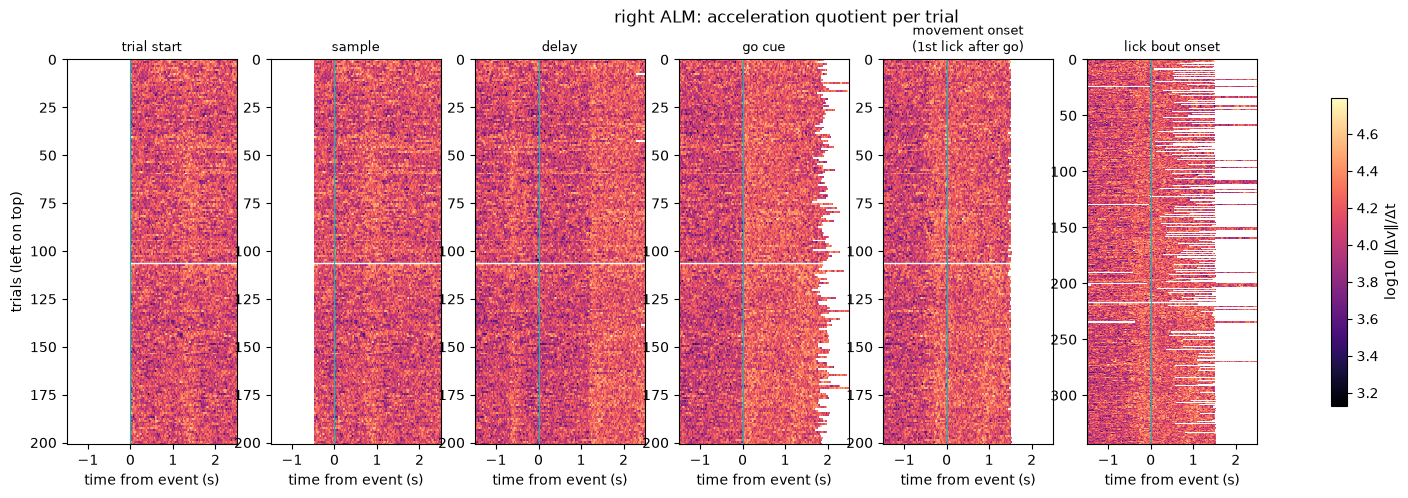

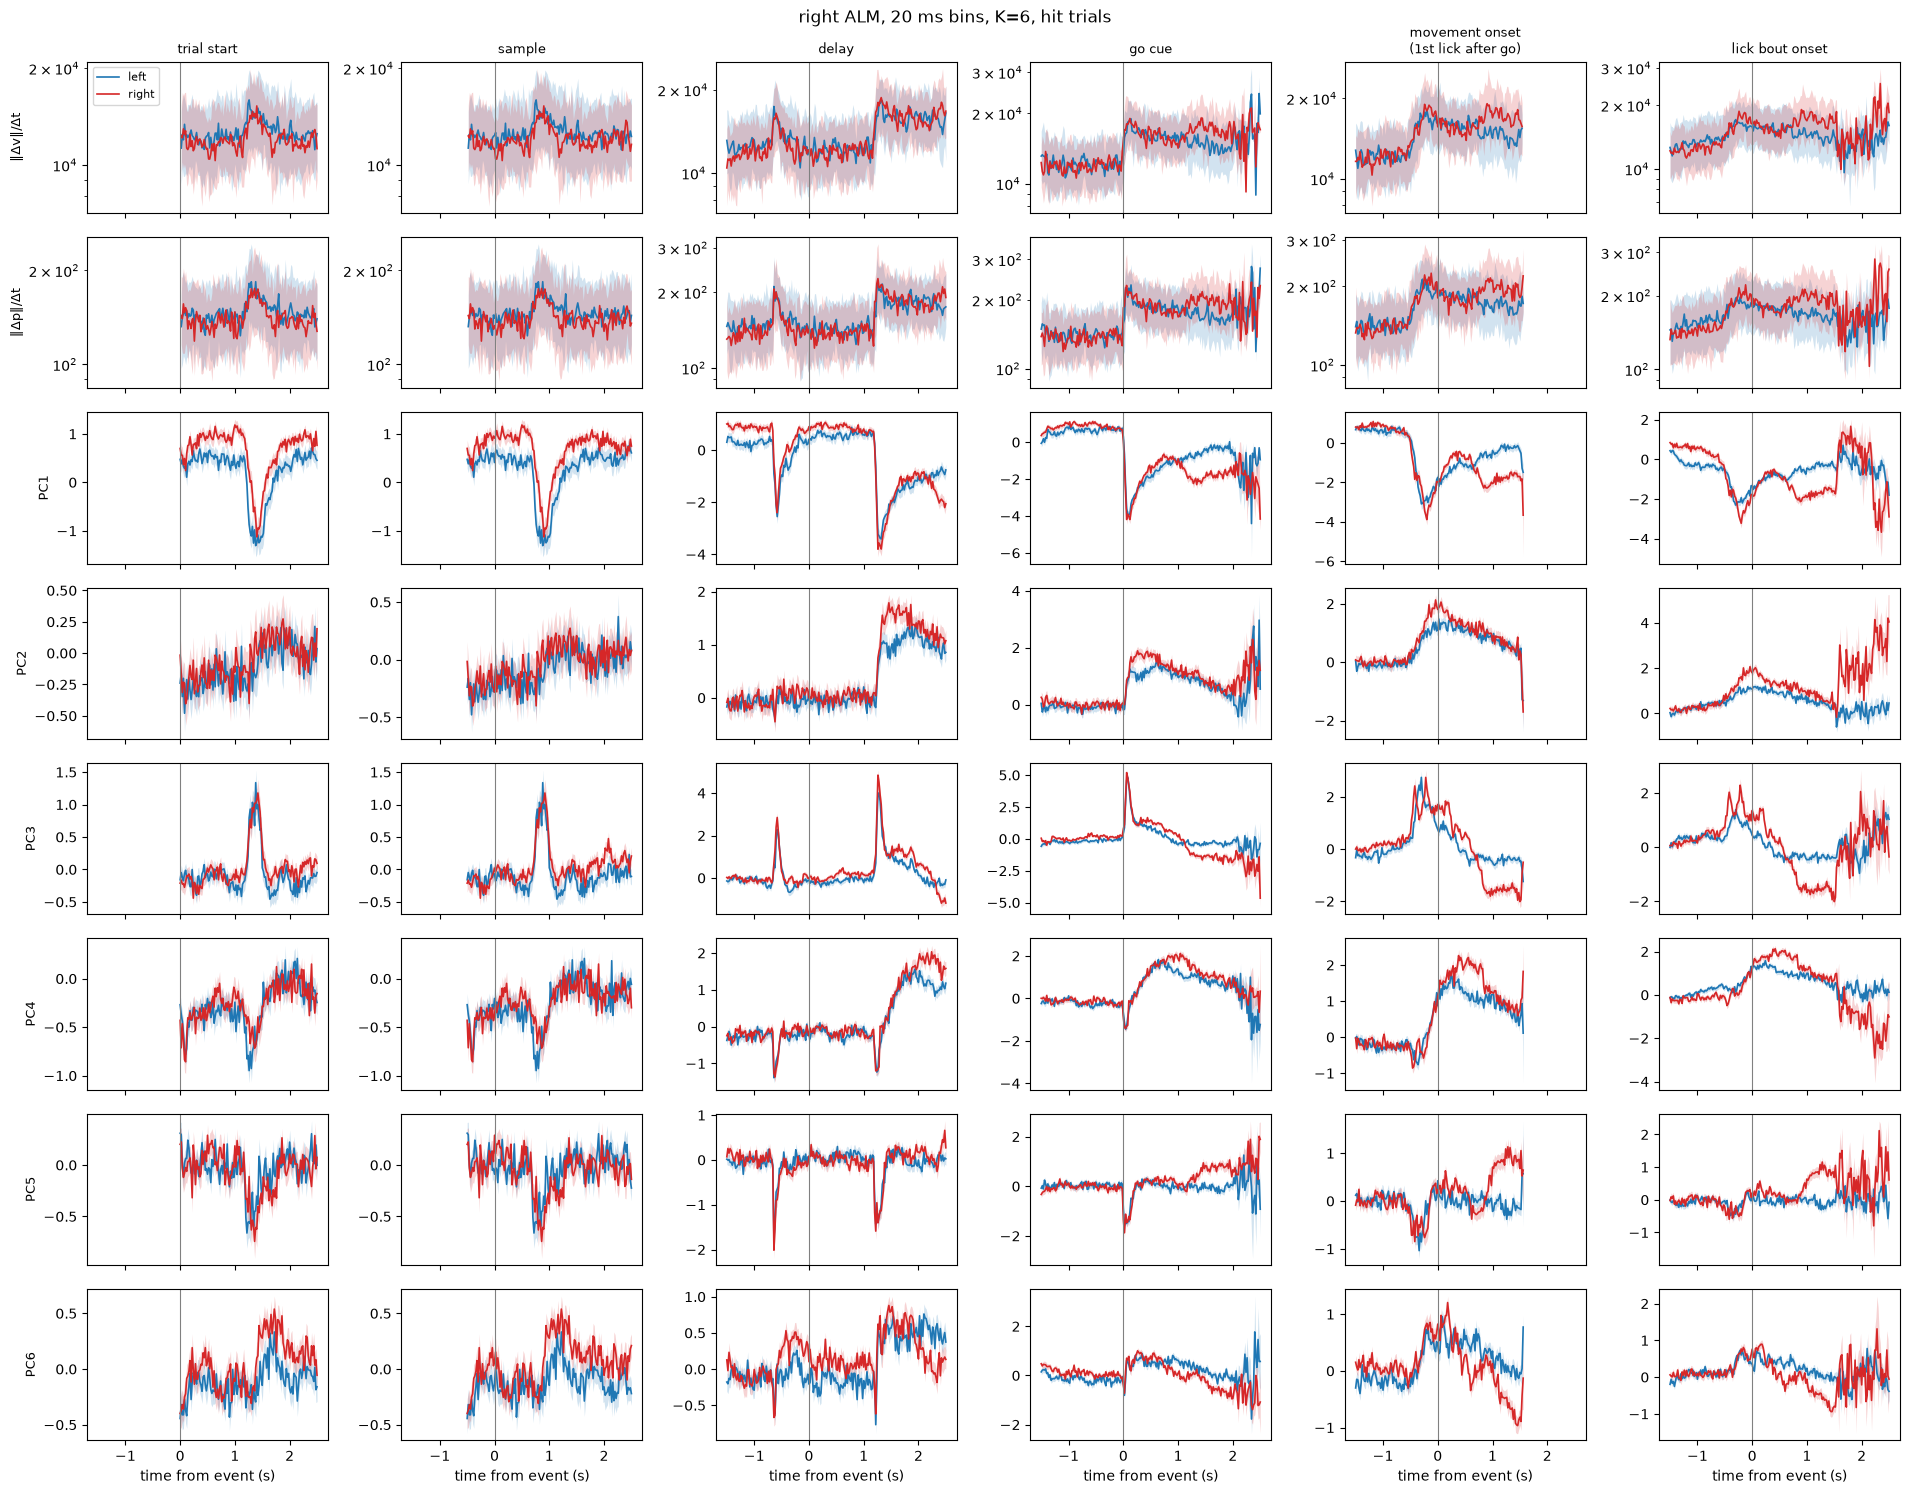

In [16]:
# ============ align to task events, left vs right trials ================
import warnings

ONLY_HITS = True          # average only correct trials
WINDOW = (-1.5, 2.5)      # seconds around each event
BOUT_GAP_S = 0.3          # licks closer than this belong to one bout

beh = nwb.acquisition["BehavioralEvents"]
ev_all = {name: np.asarray(ts.timestamps[:]) for name, ts in beh.time_series.items()}
display(pd.Series({k: len(v) for k, v in ev_all.items()}, name="n events").to_frame())


def find_ev(*subs):
    """First BehavioralEvents series whose name contains all substrings."""
    for k, v in ev_all.items():
        if all(s in k.lower() for s in subs):
            return v
    print("no event series matching", subs)
    return np.array([])


T = len(trials_df)
starts_r = trials_df["start_time"].values
stops_r = trials_df["stop_time"].values


def first_in_trial(times, after=None):
    """First event of `times` in each trial (optionally after a per-trial time)."""
    out = np.full(T, np.nan)
    for i, (s, e) in enumerate(zip(starts_r, stops_r)):
        lo = s
        if after is not None:
            if np.isnan(after[i]):
                continue
            lo = after[i]
        m = times[(times >= lo) & (times < e)]
        if m.size:
            out[i] = m.min()
    return out


sample_t = first_in_trial(find_ev("sample"))
delay_t = first_in_trial(find_ev("delay"))
go_t = first_in_trial(find_ev("go"))
licks = np.sort(np.r_[find_ev("left", "lick"), find_ev("right", "lick")])
move_t = first_in_trial(licks, after=go_t)   # movement onset = first lick after go

# lick bouts: first lick after a pause > BOUT_GAP_S, kept if inside a trial
bout_on = licks[np.r_[True, np.diff(licks) > BOUT_GAP_S]] if licks.size else licks
bk = np.searchsorted(starts_r, bout_on, side="right") - 1
ok = (bk >= 0) & (bout_on < stops_r[np.clip(bk, 0, None)])
bout_on, bout_trial = bout_on[ok], bk[ok]

trial_idx = np.arange(T)
alignments = {
    "trial start": (starts_r, trial_idx),
    "sample": (sample_t, trial_idx),
    "delay": (delay_t, trial_idx),
    "go cue": (go_t, trial_idx),
    "movement onset\n(1st lick after go)": (move_t, trial_idx),
    "lick bout onset": (bout_on, bout_trial),
}

instr = (trials_df["trial_instruction"].astype(str).str.lower().values
         if "trial_instruction" in trials_df else np.array(["all"] * T))
use = (trials_df["outcome"].astype(str).str.lower().values == "hit"
       if ONLY_HITS and "outcome" in trials_df else np.ones(T, bool))
conds = [c for c in ("left", "right") if c in set(instr)] or ["all"]
colors = {"left": "tab:blue", "right": "tab:red", "all": "k"}

off = np.arange(int(np.floor(WINDOW[0] / dt_r)), int(np.ceil(WINDOW[1] / dt_r)) + 1)
t_rel = off * dt_r


def aligned(signal, ev_t, ev_trial):
    """events x offsets of `signal`; NaN wherever the window leaves the event's trial."""
    keep = ~np.isnan(ev_t) & use[ev_trial]
    ev_t, ev_trial = ev_t[keep], ev_trial[keep]
    idx = np.searchsorted(tb_r, ev_t)[:, None] + off[None, :]
    inb = (idx >= 0) & (idx < len(tb_r))
    idxc = np.clip(idx, 0, len(tb_r) - 1)
    out = np.where(inb & (trial_r[idxc] == ev_trial[:, None]), signal[idxc], np.nan)
    return out, ev_trial


# event counts actually used
display(pd.DataFrame({
    name: {c: int(np.sum(~np.isnan(t) & use[tr] & (instr[tr] == c))) for c in conds}
    for name, (t, tr) in alignments.items()
}).rename(columns=lambda s: s.replace("\n", " ")))

# ---- figure 1: ||dv||/dt heatmaps, trials sorted left then right --------
fig, axes = plt.subplots(1, len(alignments), figsize=(3.2 * len(alignments), 5),
                         sharey=False)
for ax, (name, (t, tr)) in zip(axes, alignments.items()):
    M, mtr = aligned(Lv_r, t, tr)
    order = np.argsort(instr[mtr], kind="stable")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        im = ax.imshow(np.log10(M[order]), aspect="auto", interpolation="nearest",
                       extent=[t_rel[0], t_rel[-1], len(M), 0], cmap="magma")
    n_first = int(np.sum(instr[mtr] == conds[0]))
    ax.axhline(n_first, color="w", lw=1)
    ax.axvline(0, color="c", lw=0.8)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("time from event (s)")
axes[0].set_ylabel("trials (%s on top)" % conds[0])
fig.colorbar(im, ax=axes, shrink=0.8, label="log10 \u2016\u0394v\u2016/\u0394t")
fig.suptitle("%s: acceleration quotient per trial" % REGION)
plt.show()

# ---- figure 2: Lipschitz + each kept PC, aligned, left vs right ---------
signals = [("\u2016\u0394v\u2016/\u0394t", Lv_r, True),
           ("\u2016\u0394p\u2016/\u0394t", Lp_r, True)]
signals += [("PC%d" % (k + 1), x_r[:, k], False) for k in range(K_r)]

fig, axes = plt.subplots(len(signals), len(alignments),
                         figsize=(3.2 * len(alignments), 1.9 * len(signals)),
                         sharex=True, squeeze=False)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for col, (name, (t, tr)) in enumerate(alignments.items()):
        for row, (sname, sig, is_L) in enumerate(signals):
            ax = axes[row, col]
            M, mtr = aligned(sig, t, tr)
            for c in conds:
                m = M[instr[mtr] == c]
                if not len(m):
                    continue
                if is_L:     # quotients are heavy-tailed: median + IQR, log axis
                    mid = np.nanmedian(m, 0)
                    lo, hi = np.nanpercentile(m, [25, 75], axis=0)
                else:        # PC scores: mean +- sem
                    mid = np.nanmean(m, 0)
                    sem = np.nanstd(m, 0) / np.sqrt(np.sum(~np.isnan(m), 0).clip(1))
                    lo, hi = mid - sem, mid + sem
                ax.plot(t_rel, mid, color=colors[c], lw=1.2, label=c)
                ax.fill_between(t_rel, lo, hi, color=colors[c], alpha=0.2, lw=0)
            if is_L:
                ax.set_yscale("log")
            ax.axvline(0, color="0.5", lw=0.8)
            if row == 0:
                ax.set_title(name, fontsize=9)
            if col == 0:
                ax.set_ylabel(sname, fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("time from event (s)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("%s, %g ms bins, K=%d, %s trials" % (
    REGION, BIN_MS_R, K_r, "hit" if ONLY_HITS else "all"))
plt.tight_layout()
plt.show()


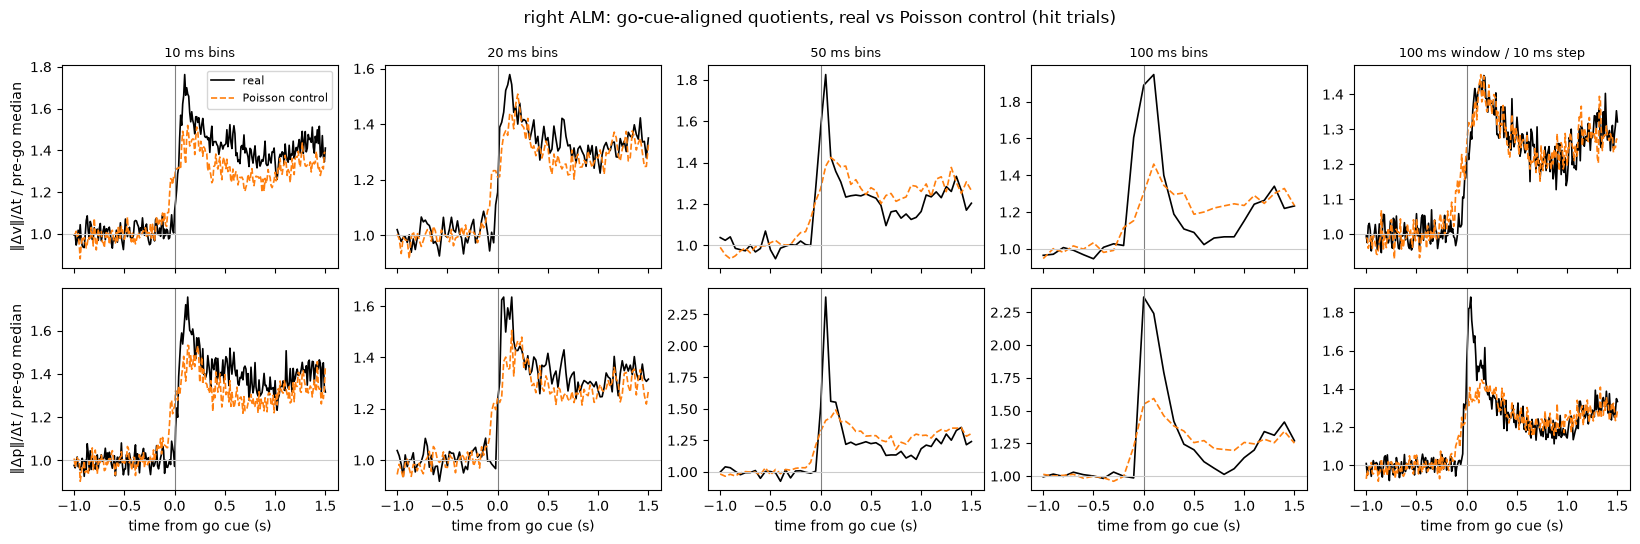

In [17]:
# ======= bin width / sliding window vs a Poisson control, right ALM =======
from scipy.ndimage import gaussian_filter1d

STEP_MS = 10.0                       # finest grid; windows are built from it
SETTINGS = [(10, 10), (20, 20), (50, 50), (100, 100), (100, 10)]  # (window, step) ms
SURR_SMOOTH_MS = 100.0               # rate estimate for the Poisson control
GO_WIN = (-1.0, 1.5)                 # seconds around the go cue
rng = np.random.default_rng(0)

# --- fine within-trial bins (same layout as cell 1) ---
edges, valid, tob = [], [], []
for ti, (s, e) in enumerate(zip(trials_df["start_time"].values,
                                trials_df["stop_time"].values)):
    n = int(np.floor((e - s) / (STEP_MS / 1000)))
    if n < 3:
        continue
    if edges:
        valid.append(False)
        tob.append(-1)
    edges.extend(s + STEP_MS / 1000 * np.arange(n + 1))
    valid.extend([True] * n)
    tob.extend([ti] * n)
edges, valid, tob = np.asarray(edges), np.asarray(valid), np.asarray(tob)
tb_f = (edges[:-1] + STEP_MS / 2000)[valid]
trial_f = tob[valid]
Xf = np.empty((valid.sum(), len(ru)), dtype=np.float32)
for j, st in enumerate(ru["spike_times"]):
    Xf[:, j] = np.histogram(st, bins=edges)[0][valid]

# --- Poisson control: same slow rates per trial, no fast structure ---
Xsur = np.empty_like(Xf)
for ti in np.unique(trial_f):
    m = trial_f == ti
    rate = gaussian_filter1d(Xf[m], SURR_SMOOTH_MS / STEP_MS, axis=0, mode="nearest")
    Xsur[m] = rng.poisson(np.clip(rate, 0, None))


def window_counts(X, w_ms, s_ms):
    """Spike counts in windows of w_ms, stepped by s_ms, never crossing a trial."""
    nw, ns = int(round(w_ms / STEP_MS)), int(round(s_ms / STEP_MS))
    out, tt, tr = [], [], []
    for ti in np.unique(trial_f):
        m = np.flatnonzero(trial_f == ti)
        if len(m) < nw + 2 * ns:
            continue
        c = np.vstack([np.zeros((1, X.shape[1])), np.cumsum(X[m], 0)])
        st = np.arange(0, len(m) - nw + 1, ns)
        out.append(c[st + nw] - c[st])
        tt.append(tb_f[m][st] - STEP_MS / 2000 + w_ms / 2000)   # window centre
        tr.append(np.full(len(st), ti))
    return np.vstack(out), np.concatenate(tt), np.concatenate(tr)


def quotients(X, tr, dt):
    ev, vec, Z = corr_svd(X)
    K = elbow_k(ev, K_MAX_R)
    x = Z @ vec[:, :K]
    sp = np.r_[False, tr[1:] == tr[:-1]]
    sn = np.r_[tr[:-1] == tr[1:], False]
    Lp = np.full(len(x), np.nan)
    Lp[1:] = np.linalg.norm(np.diff(x, axis=0), axis=1) / dt
    Lp[~sp] = np.nan
    Lv = np.full(len(x), np.nan)
    Lv[1:-1] = np.linalg.norm(x[2:] - 2 * x[1:-1] + x[:-2], axis=1) / dt**2
    Lv[~(sp & sn)] = np.nan
    return Lp, Lv, K


def go_aligned(sig, tt, tr, dt):
    off = np.arange(int(np.floor(GO_WIN[0] / dt)), int(np.ceil(GO_WIN[1] / dt)) + 1)
    keep = ~np.isnan(go_t) & use
    ev_t, ev_tr = go_t[keep], np.flatnonzero(keep)
    idx = np.searchsorted(tt, ev_t)[:, None] + off[None, :]
    idxc = np.clip(idx, 0, len(tt) - 1)
    ok = (idx >= 0) & (idx < len(tt)) & (tr[idxc] == ev_tr[:, None])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return off * dt, np.nanmedian(np.where(ok, sig[idxc], np.nan), 0)


rows = []
fig, axes = plt.subplots(2, len(SETTINGS), figsize=(3.3 * len(SETTINGS), 5.5),
                         sharex=True, squeeze=False)
for col, (w, s) in enumerate(SETTINGS):
    dt_s = s / 1000.0
    label = "%d ms bins" % w if w == s else "%d ms window / %d ms step" % (w, s)
    for kind, X, ls in (("real", Xf, "-"), ("Poisson control", Xsur, "--")):
        Xw, tt, tr = window_counts(X, w, s)
        Lp, Lv, K = quotients(Xw, tr, dt_s)
        for row, (name, sig) in enumerate((("\u2016\u0394v\u2016/\u0394t", Lv),
                                           ("\u2016\u0394p\u2016/\u0394t", Lp))):
            t_rel, med = go_aligned(sig, tt, tr, dt_s)
            base = np.nanmedian(med[t_rel < 0])
            axes[row, col].plot(t_rel, med / base, ls, lw=1.2,
                                color="k" if kind == "real" else "tab:orange",
                                label=kind)
            if row == 0:
                post = np.nanmedian(med[(t_rel > 0.2) & (t_rel < 1.0)])
                go_step = post / base
        rows.append({"setting": label, "data": kind, "K": K,
                     "Lv/Lp (median)": np.nanmedian(Lv) / np.nanmedian(Lp),
                     "noise-only Lv/Lp": np.sqrt(3) / dt_s if w == s else np.nan,
                     "go-cue step (Lv post/pre)": go_step})
    axes[0, col].set_title(label, fontsize=9)
    for row in range(2):
        axes[row, col].axvline(0, color="0.5", lw=0.8)
        axes[row, col].axhline(1, color="0.8", lw=0.8)
axes[0, 0].set_ylabel("\u2016\u0394v\u2016/\u0394t / pre-go median")
axes[1, 0].set_ylabel("\u2016\u0394p\u2016/\u0394t / pre-go median")
for ax in axes[-1]:
    ax.set_xlabel("time from go cue (s)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("%s: go-cue-aligned quotients, real vs Poisson control (hit trials)" % REGION)
plt.tight_layout()
plt.show()

display(pd.DataFrame(rows).set_index(["setting", "data"]).style.format({
    "Lv/Lp (median)": "{:.1f}", "noise-only Lv/Lp": "{:.1f}",
    "go-cue step (Lv post/pre)": "{:.2f}"}, na_rep="\u2013"))


wedge check OK at bin 64676; 15 PC pairs


instruction,left,right
outcome,,
hit,106,95
ignore,130,111
miss,29,53


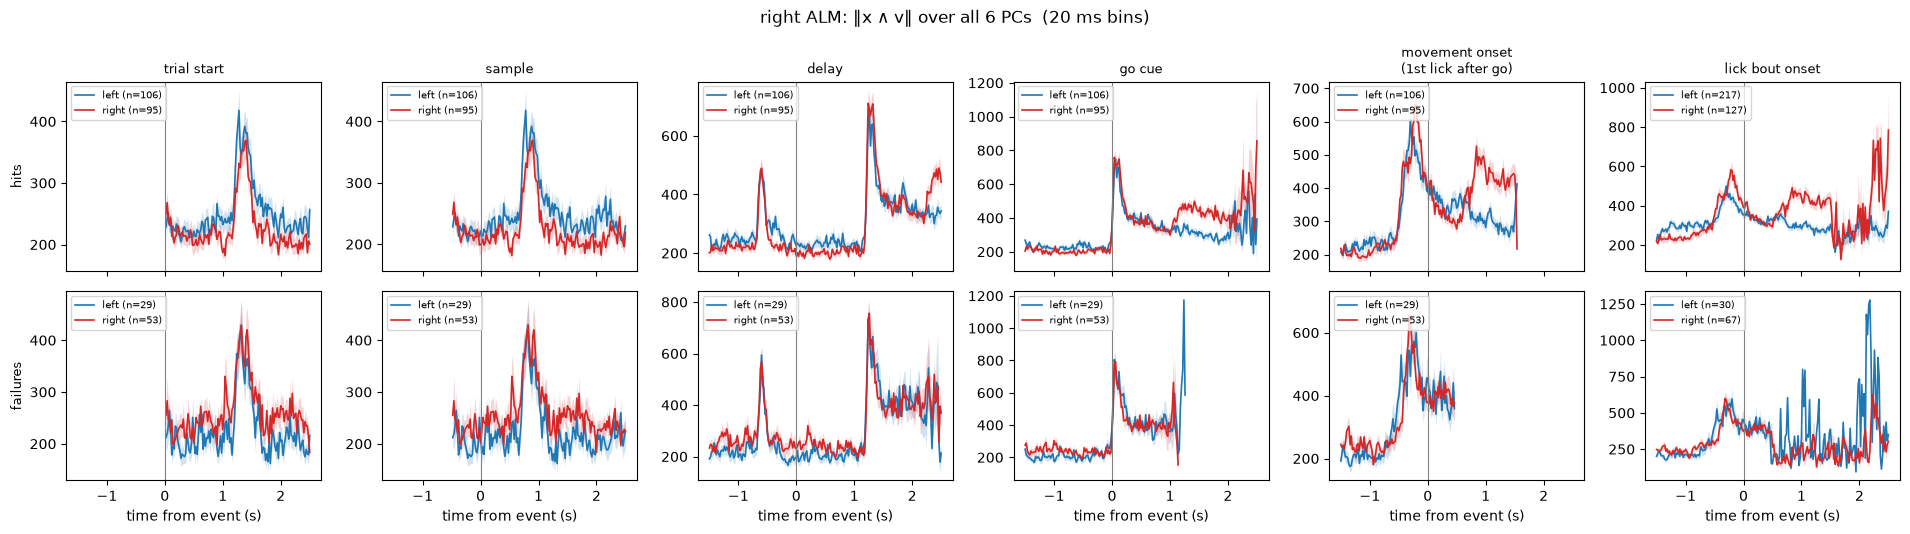

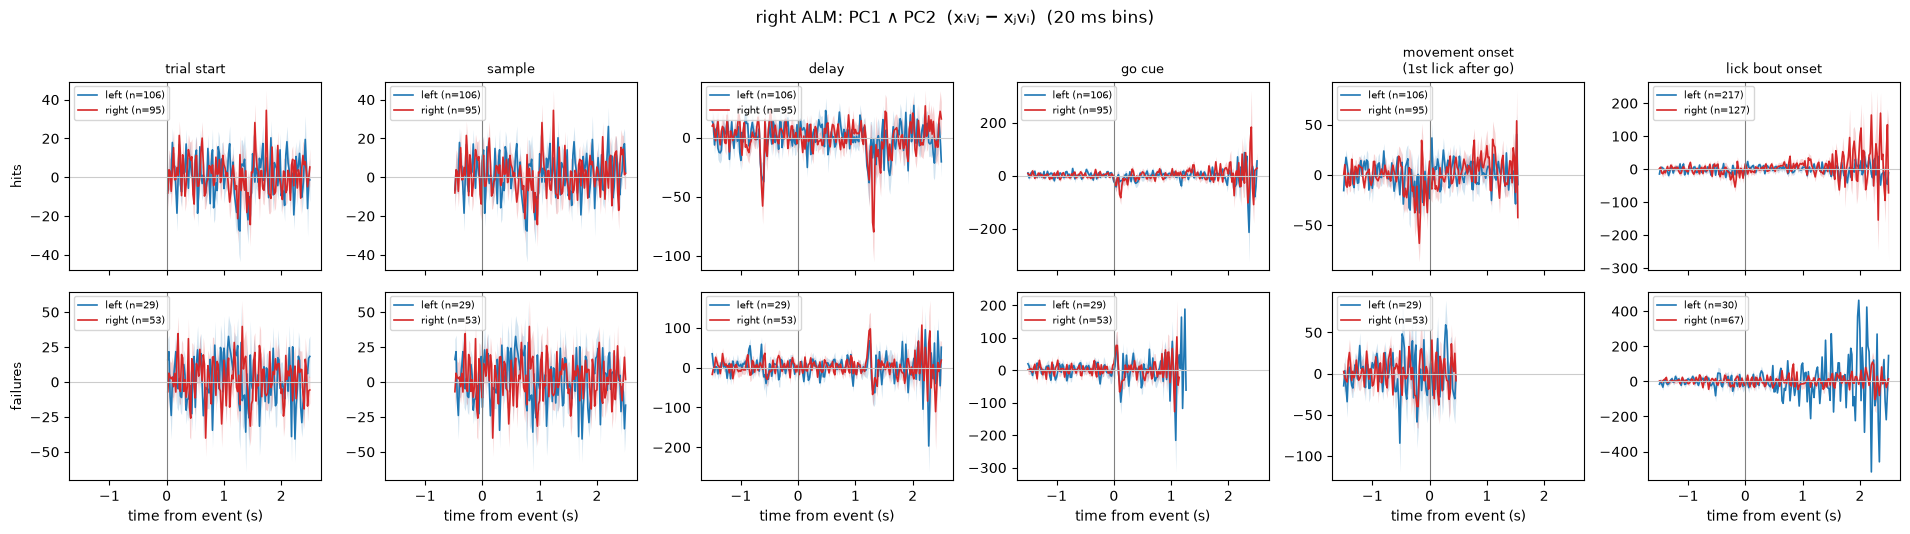

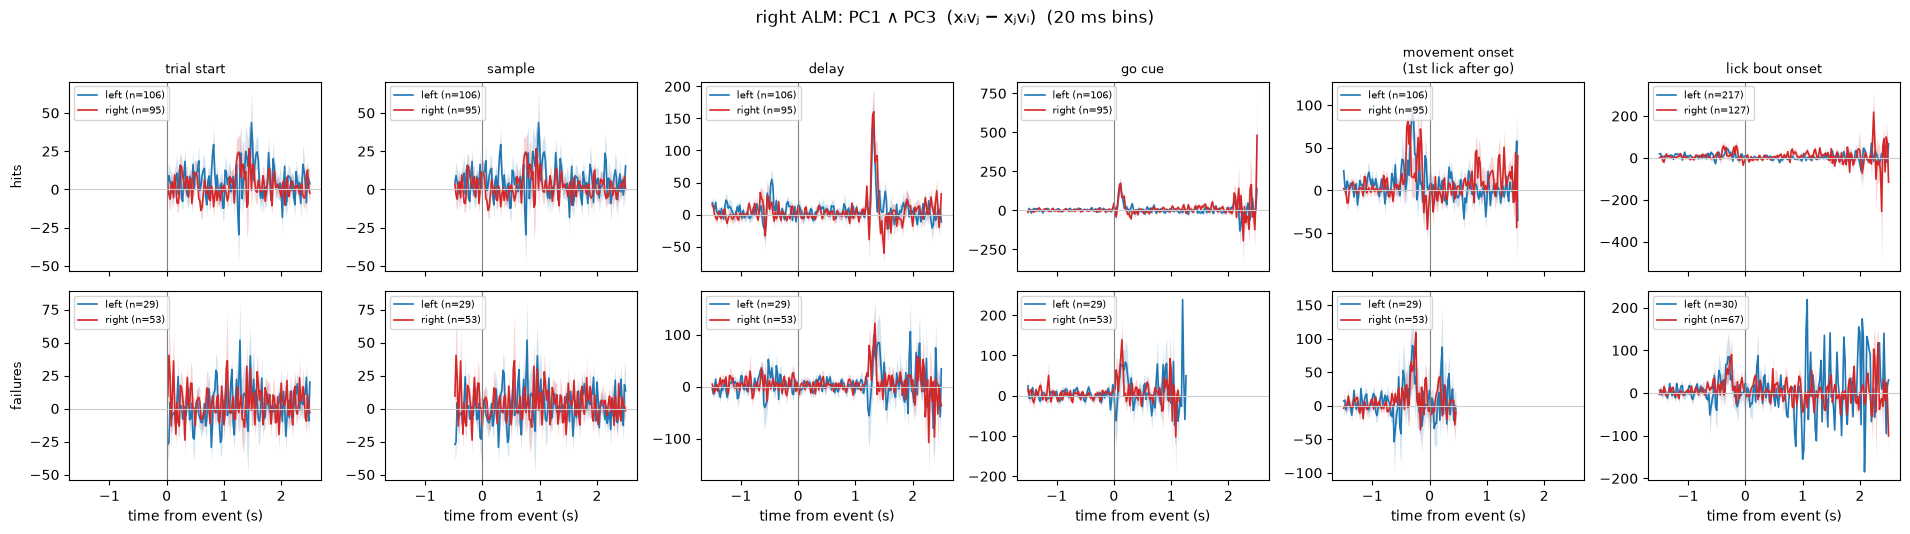

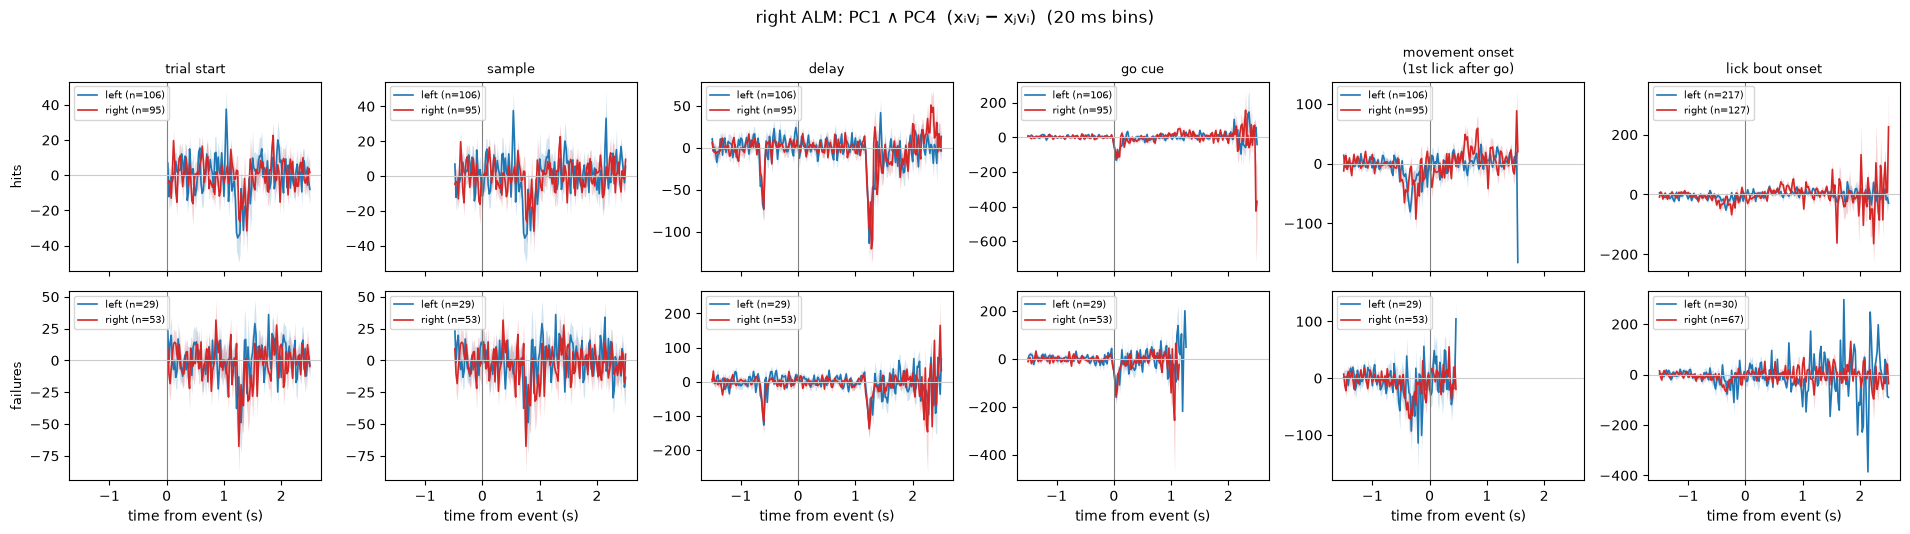

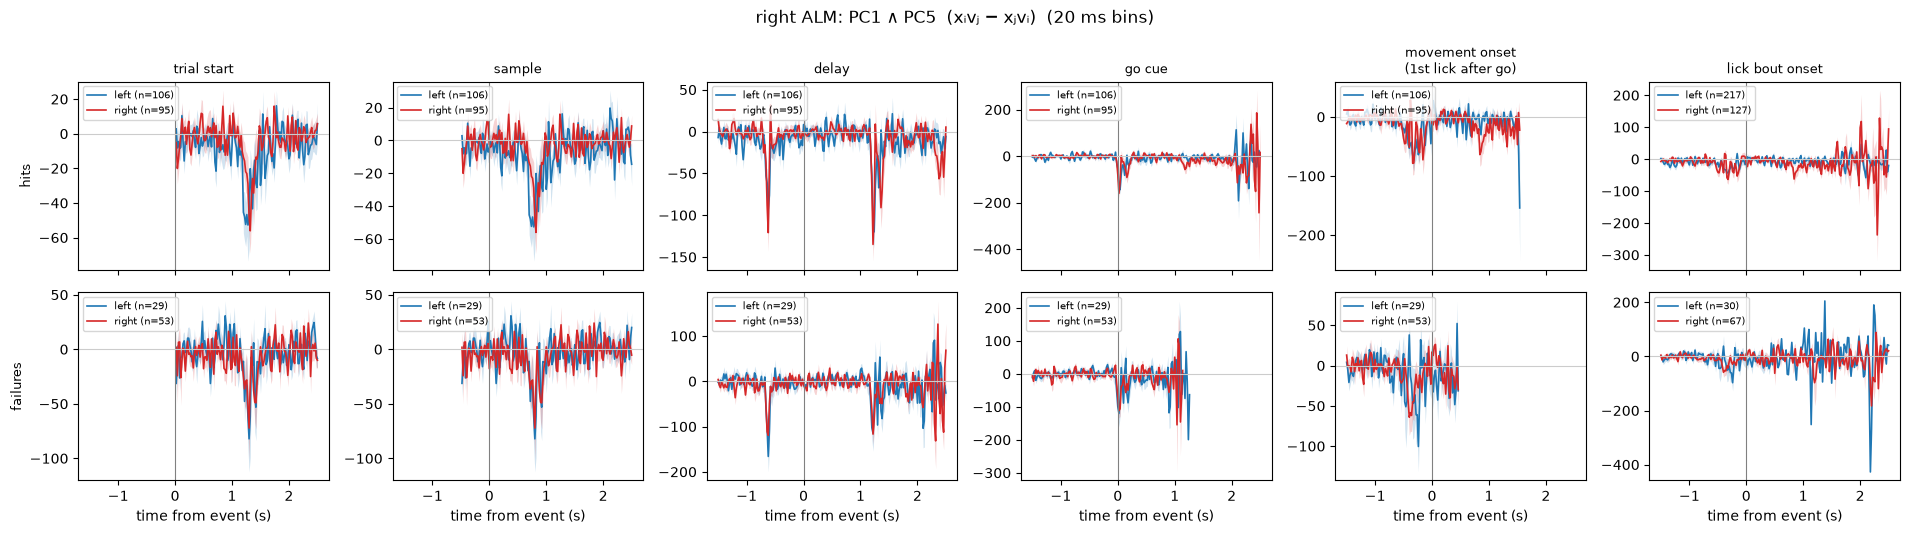

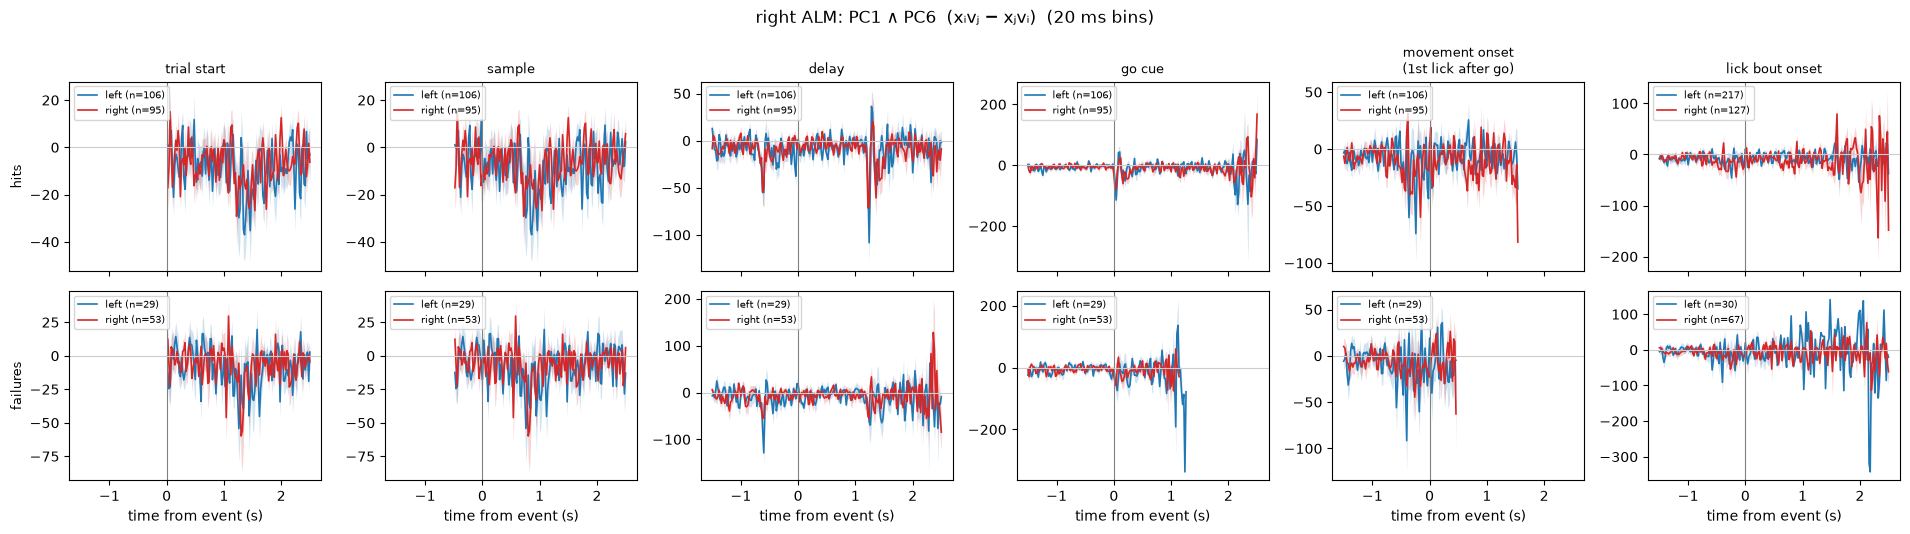

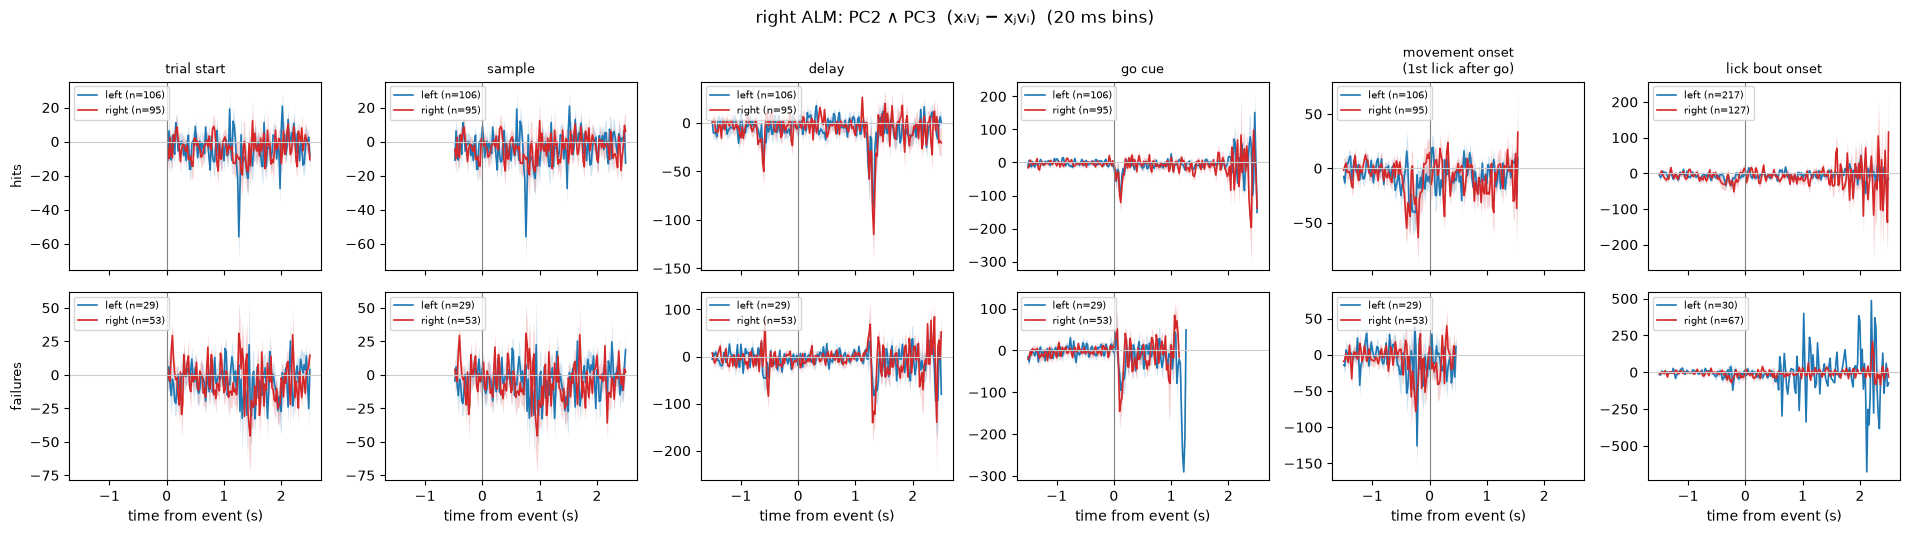

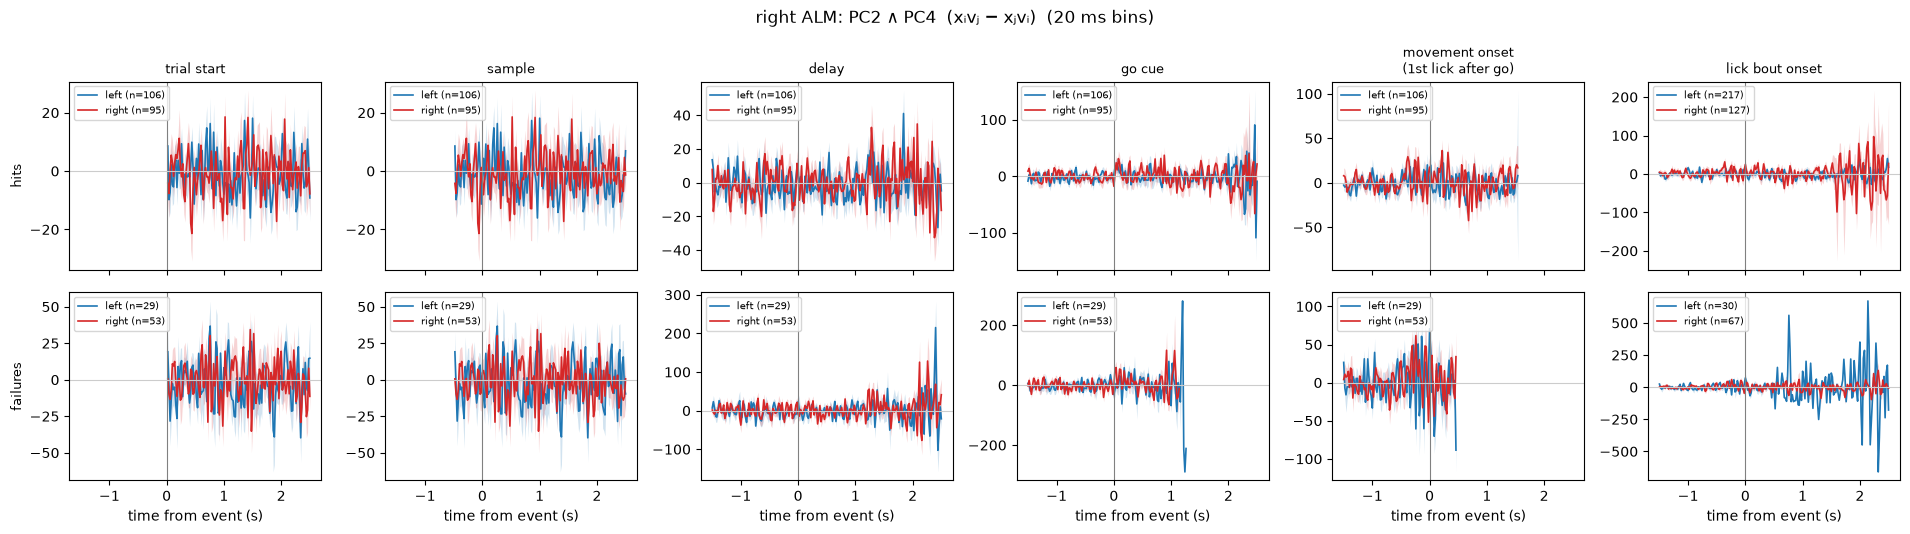

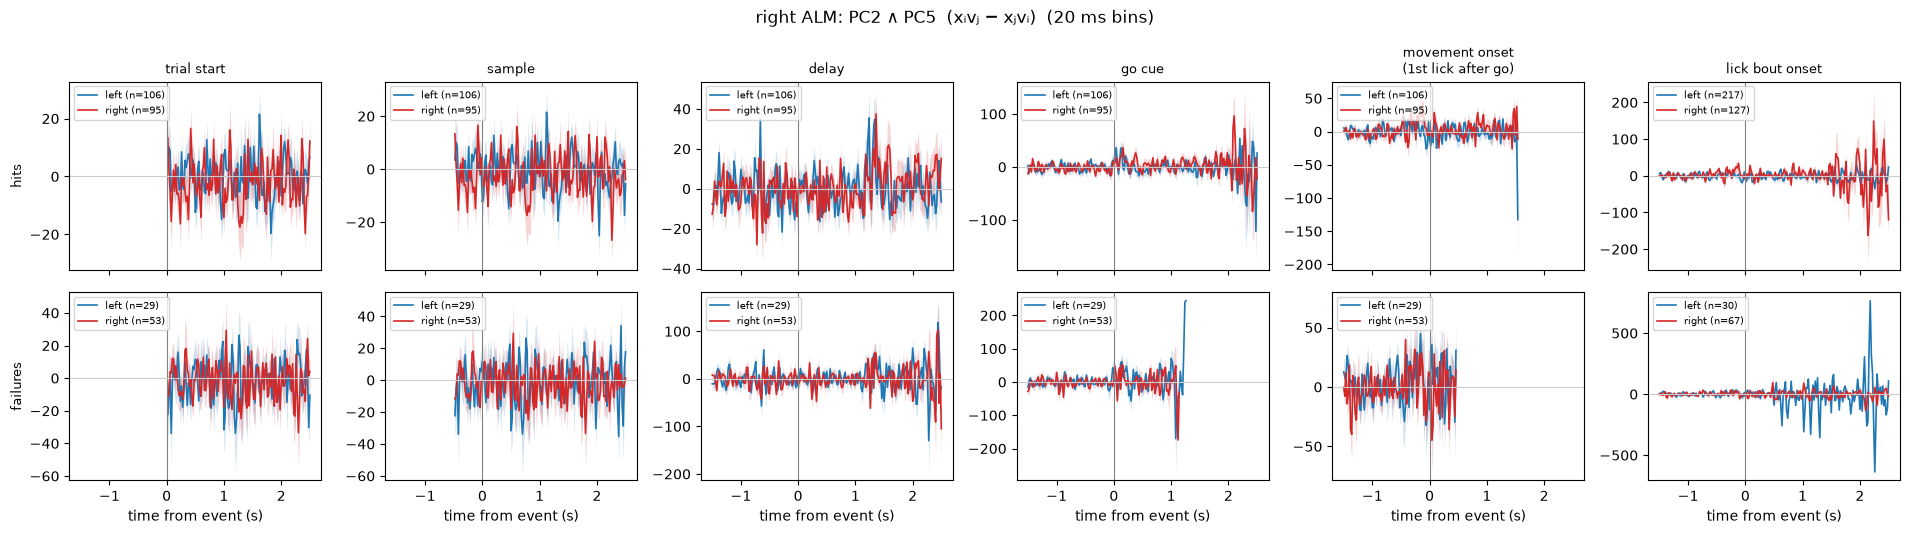

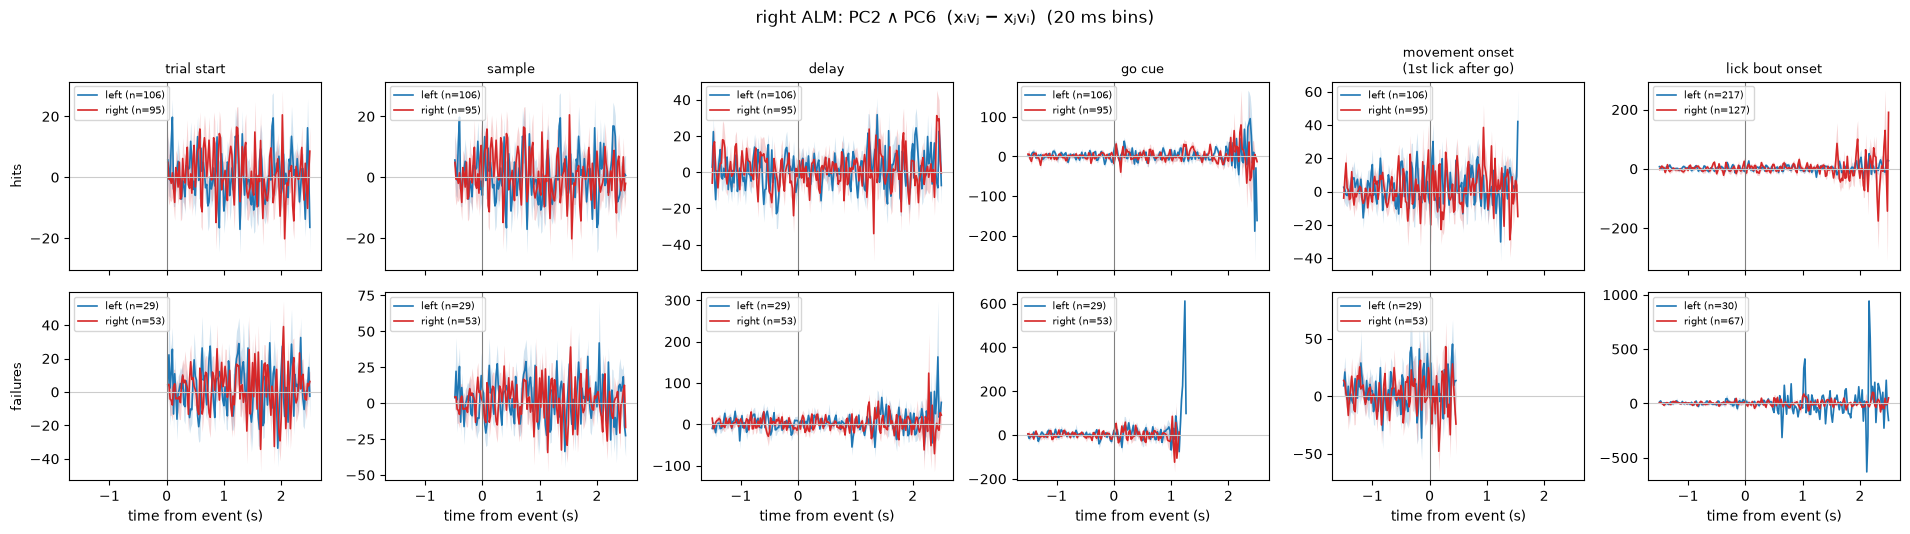

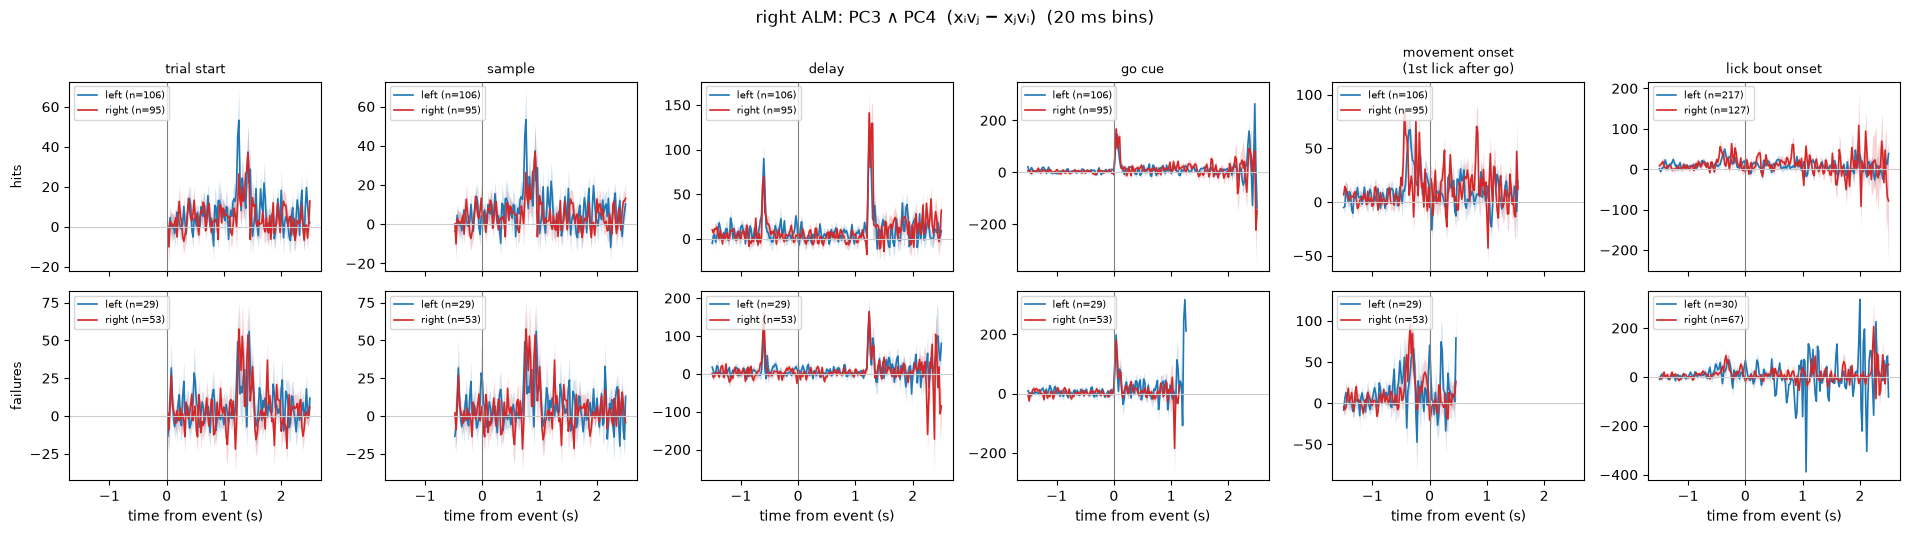

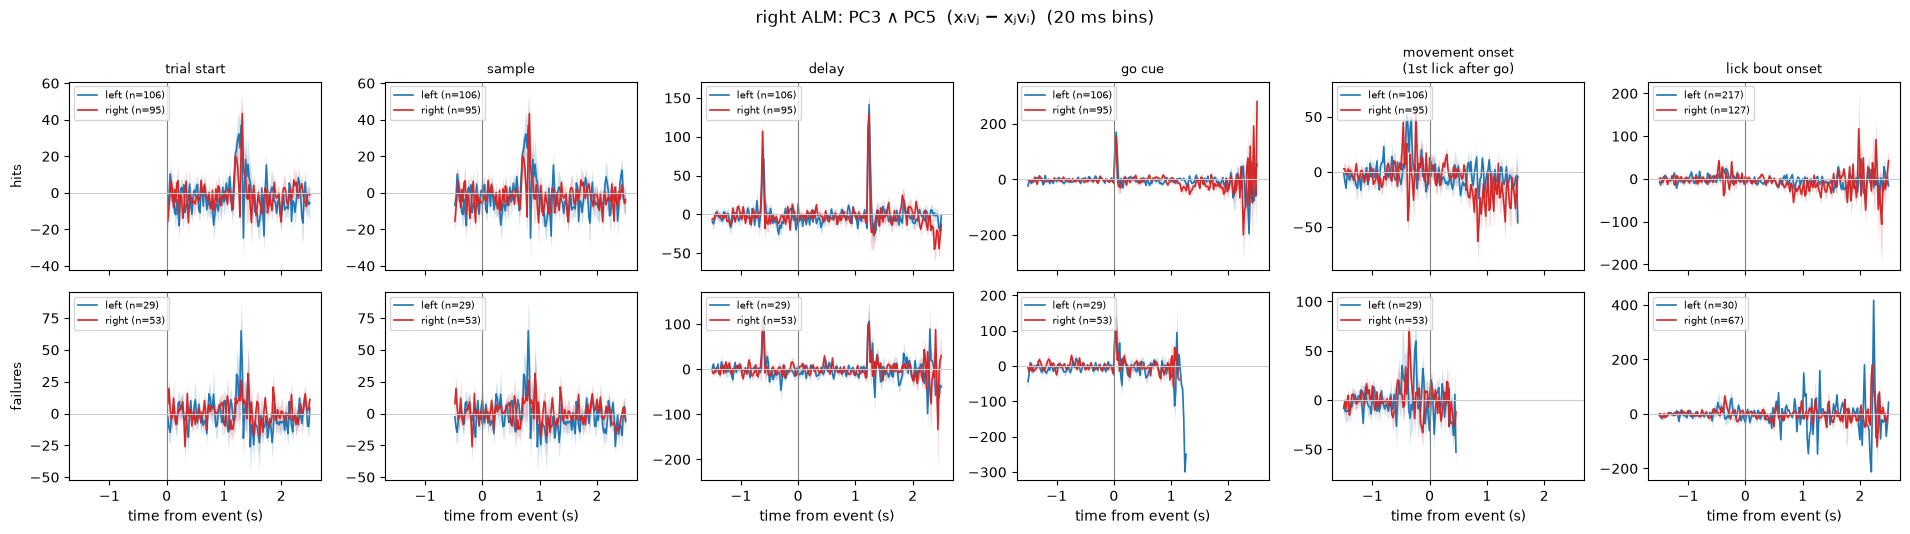

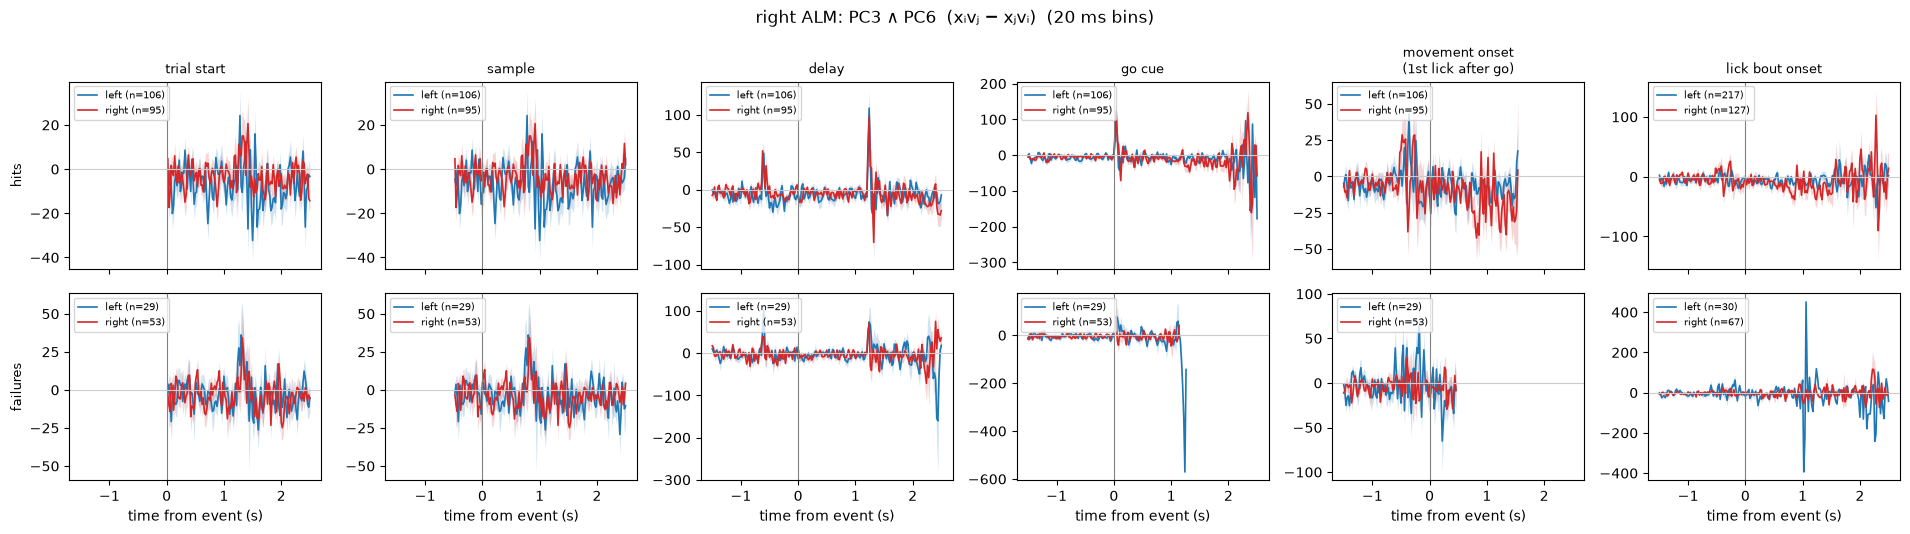

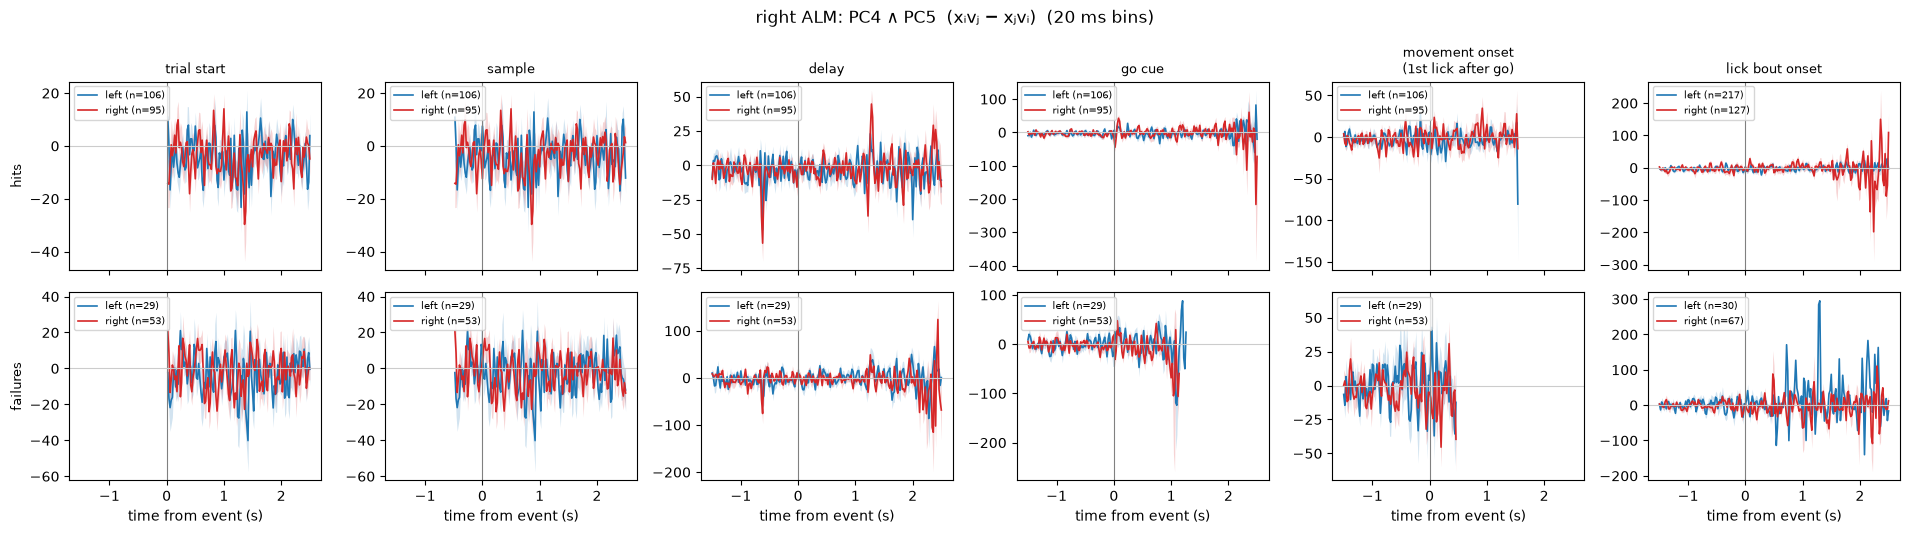

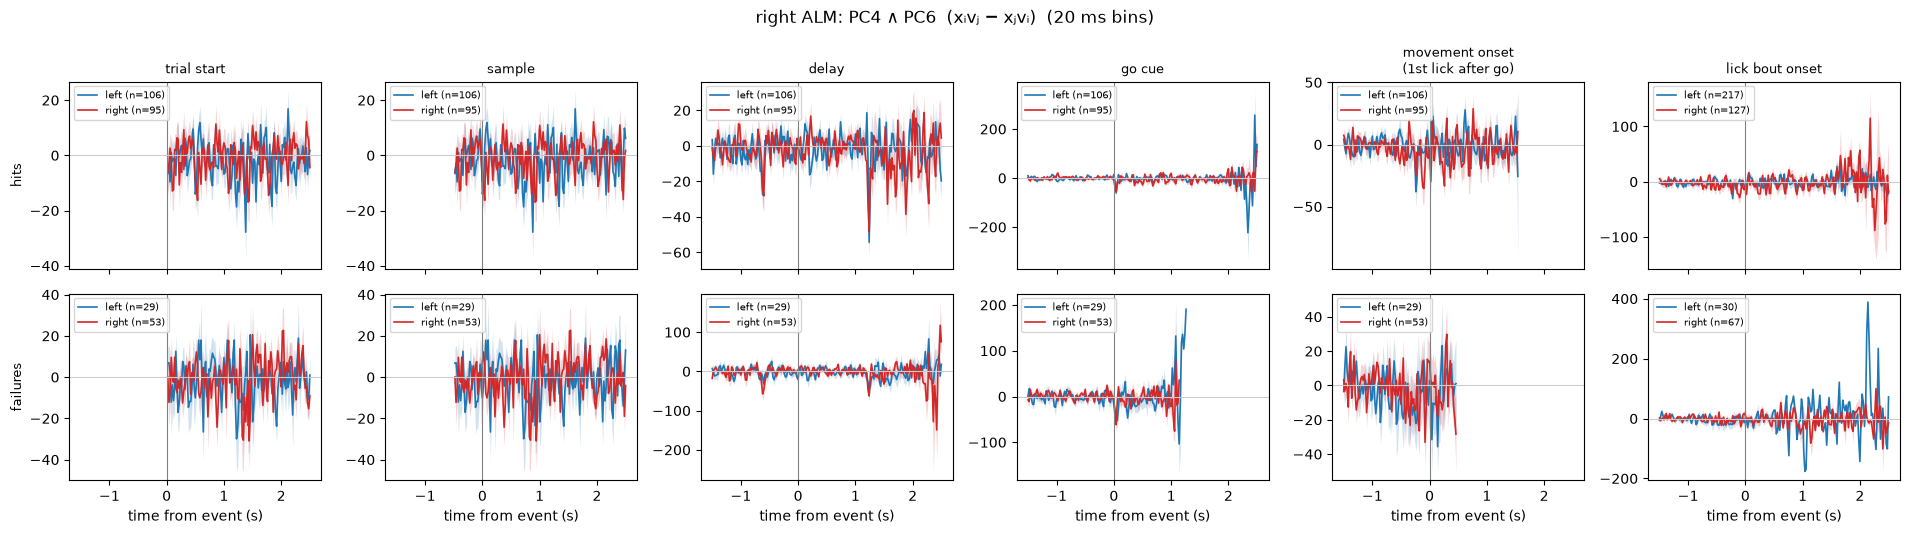

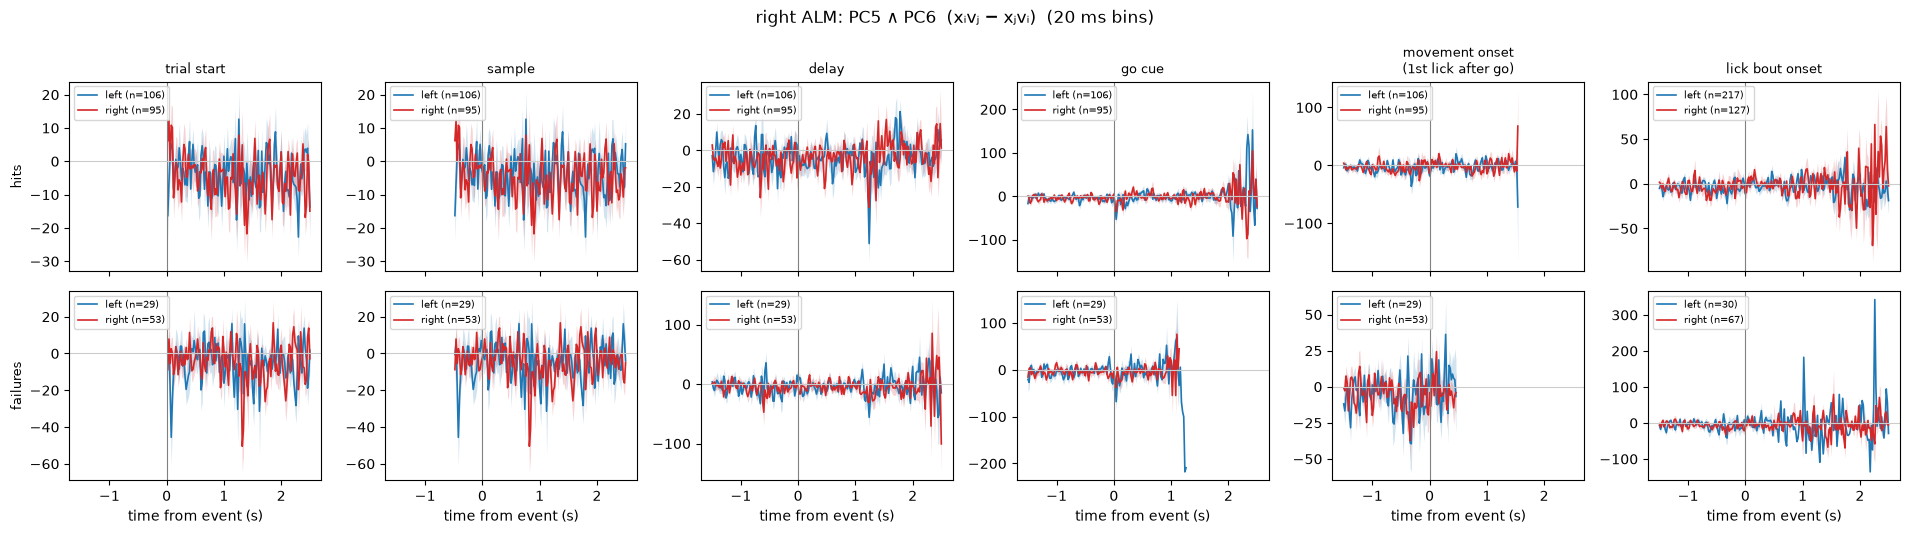

In [22]:
# ===== wedge products x(t) ∧ v(t) in PC space, aligned to task events =====
import warnings
from itertools import combinations

from itertools import combinations


def compute_wedge_product(components, k):
    """Wedge product of the first k columns of `components` (n_features, n_components).

    Coefficients are the determinants of every k x k row-submatrix;
    keys are the basis tuples, e.g. (0, 1) for e0 ∧ e1."""
    n_features, n_components = components.shape
    if k > n_features or k > n_components:
        raise ValueError("k cannot exceed the number of features or available components.")
    sub = components[:, :k]
    wedge_vector = {}
    for basis in combinations(range(n_features), k):
        coef = np.linalg.det(sub[list(basis), :])
        if not np.isclose(coef, 0.0):
            wedge_vector[basis] = coef
    return wedge_vector


def wedge_magnitude(wedge_dict):
    """Euclidean norm of a wedge product."""
    return np.sqrt(sum(val**2 for val in wedge_dict.values()))


def wedge_inner_product(wedge_A, wedge_B):
    """Inner product between two wedge products (Grassmannian overlap)."""
    return sum(val * wedge_B[b] for b, val in wedge_A.items() if b in wedge_B)


FAIL_OUTCOMES = ("miss",)        # add "ignore" to include no-response trials
PAIRS = list(combinations(range(K_r), 2))
off = np.arange(int(np.floor(WINDOW[0] / dt_r)), int(np.ceil(WINDOW[1] / dt_r)) + 1)
t_rel = off * dt_r

# velocity: central difference inside a trial, NaN at trial edges
v_r = np.full_like(x_r, np.nan)
inner = np.r_[False, trial_r[2:] == trial_r[:-2], False]
v_r[1:-1] = (x_r[2:] - x_r[:-2]) / (2 * dt_r)
v_r[~inner] = np.nan

# bivector components for every PC pair, all bins at once
I = np.array([p[0] for p in PAIRS])
J = np.array([p[1] for p in PAIRS])
W = x_r[:, I] * v_r[:, J] - x_r[:, J] * v_r[:, I]       # (bins, n_pairs)
W_mag = np.sqrt(np.sum(W**2, axis=1))                    # = ||x ∧ v||

# one-bin check against your compute_wedge_product (2x2 minors of [x v])
i0 = np.flatnonzero(inner)[len(np.flatnonzero(inner)) // 2]
ref = compute_wedge_product(np.column_stack([x_r[i0], v_r[i0]]), 2)
assert np.allclose([ref.get(p, 0.0) for p in PAIRS], W[i0]), "wedge mismatch"
print("wedge check OK at bin %d; %d PC pairs" % (i0, len(PAIRS)))

# trial outcome masks (trials_df already has photostim trials removed)
outc = trials_df["outcome"].astype(str).str.lower().values
is_hit = outc == "hit"
is_fail = np.isin(outc, FAIL_OUTCOMES)
display(pd.crosstab(pd.Series(outc, name="outcome"), pd.Series(instr, name="instruction")))



def aligned_by(signal, ev_t, ev_trial, trial_mask):
    """events x offsets of `signal` for trials in `trial_mask`; NaN outside the trial."""
    keep = ~np.isnan(ev_t) & trial_mask[ev_trial]
    ev_t, ev_trial = ev_t[keep], ev_trial[keep]
    idx = np.searchsorted(tb_r, ev_t)[:, None] + off[None, :]
    idxc = np.clip(idx, 0, len(tb_r) - 1)
    ok = (idx >= 0) & (idx < len(tb_r)) & (trial_r[idxc] == ev_trial[:, None])
    return np.where(ok, signal[idxc], np.nan), ev_trial


def plot_hits_vs_failures(sig, title, signed=True):
    fig, axes = plt.subplots(2, len(alignments), figsize=(3.2 * len(alignments), 5.4),
                             sharex=True, squeeze=False)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for col, (name, (t, tr)) in enumerate(alignments.items()):
            for row, (rname, mask) in enumerate((("hits", is_hit),
                                                 ("failures", is_fail))):
                ax = axes[row, col]
                M, mtr = aligned_by(sig, t, tr, mask)
                for c in conds:
                    m = M[instr[mtr] == c]
                    if not len(m):
                        continue
                    mid = np.nanmean(m, 0)
                    sem = np.nanstd(m, 0) / np.sqrt(np.sum(~np.isnan(m), 0).clip(1))
                    ax.plot(t_rel, mid, color=colors[c], lw=1.2,
                            label="%s (n=%d)" % (c, len(m)))
                    ax.fill_between(t_rel, mid - sem, mid + sem,
                                    color=colors[c], alpha=0.2, lw=0)
                ax.axvline(0, color="0.5", lw=0.8)
                if signed:
                    ax.axhline(0, color="0.8", lw=0.8)
                if row == 0:
                    ax.set_title(name, fontsize=9)
                if col == 0:
                    ax.set_ylabel(rname, fontsize=9)
                ax.legend(fontsize=7, loc="upper left")
    for ax in axes[-1]:
        ax.set_xlabel("time from event (s)")
    fig.suptitle("%s: %s  (%g ms bins)" % (REGION, title, BIN_MS_R))
    plt.tight_layout()
    plt.show()


# total wedge magnitude, then every PC pair
plot_hits_vs_failures(W_mag, "\u2016x \u2227 v\u2016 over all %d PCs" % K_r, signed=False)
for p, (i, j) in enumerate(PAIRS):
    plot_hits_vs_failures(W[:, p], "PC%d \u2227 PC%d  (x\u1d62v\u2c7c \u2212 x\u2c7cv\u1d62)"
                          % (i + 1, j + 1))
